In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [3]:
df=pd.read_csv(r'C:/Users/World/Downloads/Compressed/adult.csv')
df

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [4]:
df.shape

(48842, 15)

In [5]:
df.info()
# df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [6]:
df.select_dtypes(include=['object','category']).columns.to_frame().reset_index()[0]

0         workclass
1         education
2    marital-status
3        occupation
4      relationship
5              race
6            gender
7    native-country
8            income
Name: 0, dtype: object

In [7]:
 df.nunique()

age                   74
workclass              9
fnlwgt             28523
education             16
educational-num       16
marital-status         7
occupation            15
relationship           6
race                   5
gender                 2
capital-gain         123
capital-loss          99
hours-per-week        96
native-country        42
income                 2
dtype: int64

In [8]:
less=df.loc[df['income']=='<=50K',['income']]
greater=df.loc[df['income']=='>50K',['income']]

print(f'income<=50K :{len(less)} and income>50K : {len(greater)}')


income<=50K :37155 and income>50K : 11687


In [9]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


<Axes: xlabel='age', ylabel='Count'>

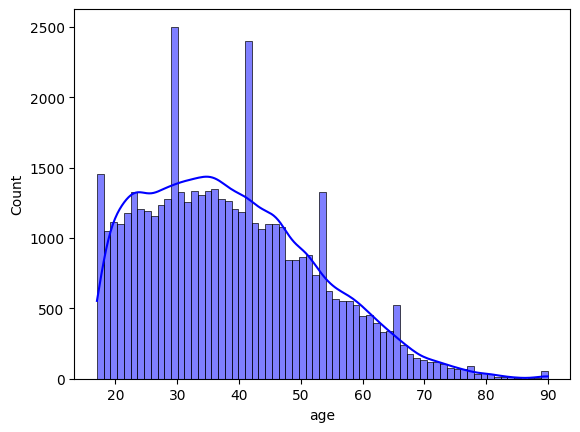

In [12]:
sns.histplot(df['age'], kde=True,color='blue',cbar=False,)

<Axes: xlabel='hours-per-week', ylabel='Count'>

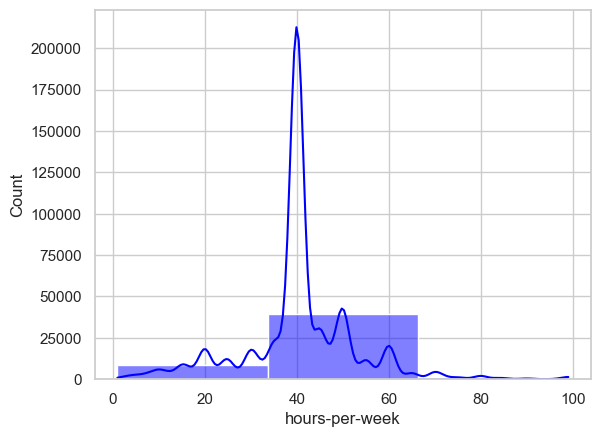

In [246]:
sns.histplot(df['hours-per-week'], kde=True,color='blue',binwidth=30)


Number of extreme values: 0


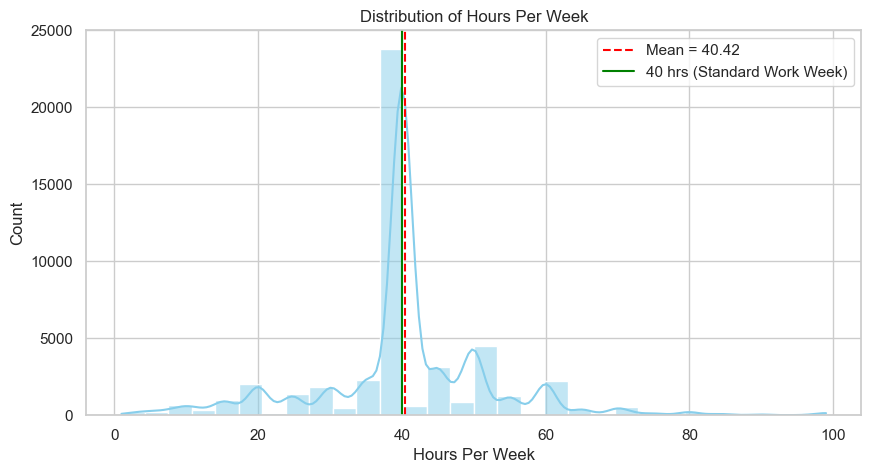

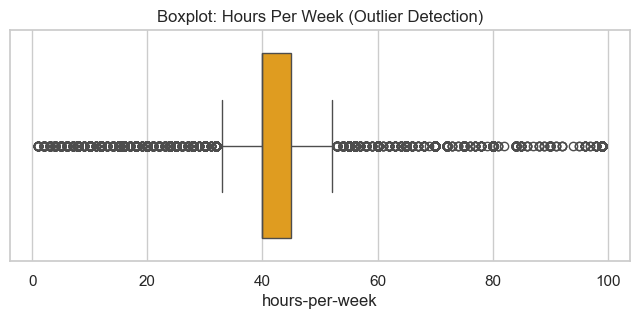

In [247]:
# --- 2. Check for extreme values (0 or > 100 hours) ---
extreme_values = df[(df['hours-per-week'] <= 0) | (df['hours-per-week'] > 100)]
print(f"\nNumber of extreme values: {extreme_values.shape[0]}")
if not extreme_values.empty:
    print(extreme_values['hours-per-week'].value_counts())

# --- 3. Visualize Distribution ---
plt.figure(figsize=(10,5))
sns.histplot(df['hours-per-week'], bins=30, kde=True, color='skyblue')
plt.axvline(df['hours-per-week'].mean(), color='red', linestyle='--', label=f"Mean = {df['hours-per-week'].mean():.2f}")
plt.axvline(40, color='green', linestyle='-', label="40 hrs (Standard Work Week)")
plt.title("Distribution of Hours Per Week")
plt.xlabel("Hours Per Week")
plt.ylabel("Count")
plt.legend()
plt.show()

# --- 4. Boxplot to Spot Outliers ---
plt.figure(figsize=(8,3))
sns.boxplot(x=df['hours-per-week'], color="orange")
plt.title("Boxplot: Hours Per Week (Outlier Detection)")
plt.show()

In [248]:
df.groupby('capital-gain').max().sort_values(by='capital-gain',ascending=False).head(1)
# print(df[df['capital-gain'] == df['capital-gain'].max()])

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-loss,hours-per-week,native-country,income
capital-gain,,,,,,,,,,,,,,
99999,80,State-gov,553405,Some-college,16,Widowed,Transport-moving,Wife,White,Male,0,99,United-States,>50K


In [249]:
df.groupby('capital-loss').max().sort_values(by='capital-loss',ascending=False).head(1)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,hours-per-week,native-country,income
capital-loss,,,,,,,,,,,,,,
4356,90,Private,186061,Some-college,10,Widowed,Exec-managerial,Unmarried,White,Female,0,40,United-States,<=50K


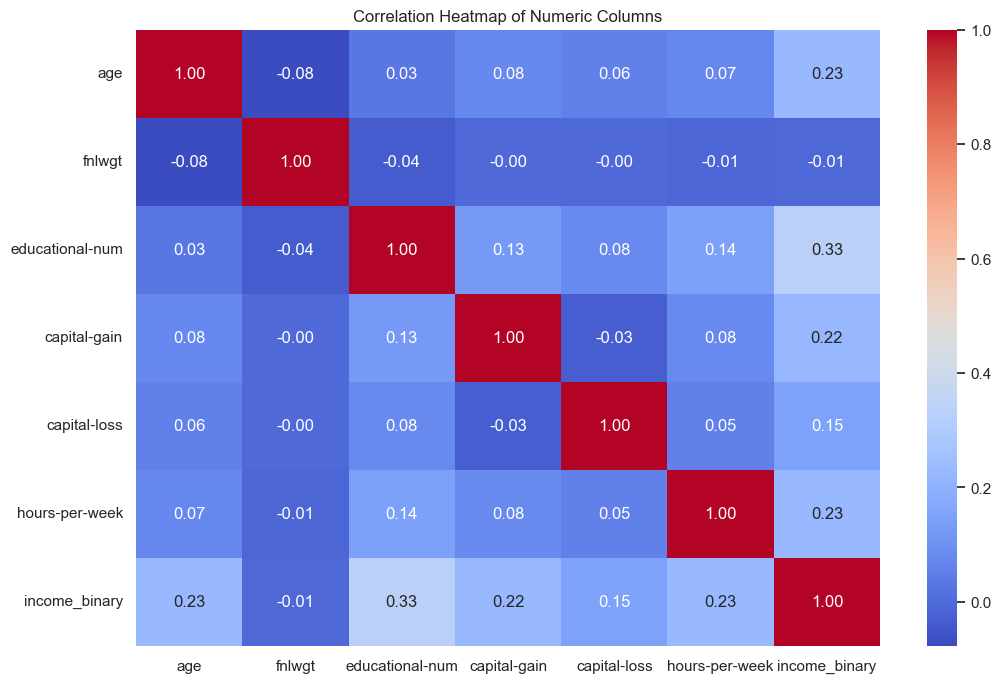

In [250]:
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)

# Select numeric columns only
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = df[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numeric Columns")
plt.show()

In [251]:
df['workclass'].value_counts(dropna=False)

workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
?                    2799
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

education
HS-grad    15784
Name: count, dtype: int64


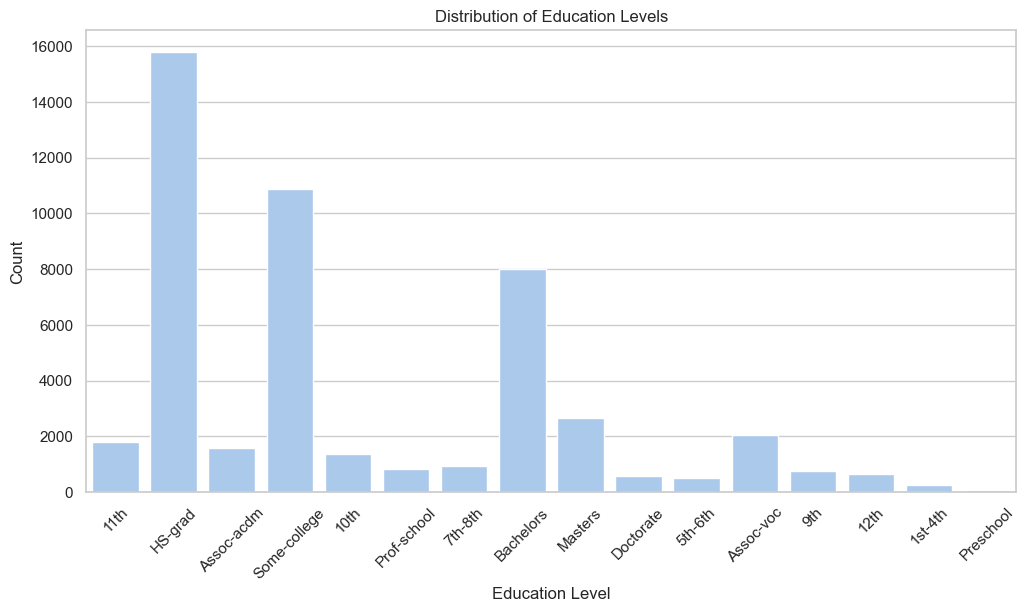

In [252]:
mustCommon=df['education'].value_counts().head(1)
print(mustCommon)
plt.figure(figsize=(12,6))
sns.countplot(x='education', data=df, )
plt.xticks(rotation=45)  # Rotate labels so they don't overlap
plt.title("Distribution of Education Levels")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.show()

In [253]:
edu_check = df.groupby("education")["educational-num"].unique().sort_values()

print(len(edu_check), "==", len(df["education"].unique()))


16 == 16


occupation
Prof-specialty       6172
Craft-repair         6112
Exec-managerial      6086
Adm-clerical         5611
Sales                5504
Other-service        4923
Machine-op-inspct    3022
?                    2809
Transport-moving     2355
Handlers-cleaners    2072
Farming-fishing      1490
Tech-support         1446
Protective-serv       983
Priv-house-serv       242
Armed-Forces           15
Name: count, dtype: int64

most common occupation
Prof-specialty    6172
Name: count, dtype: int64


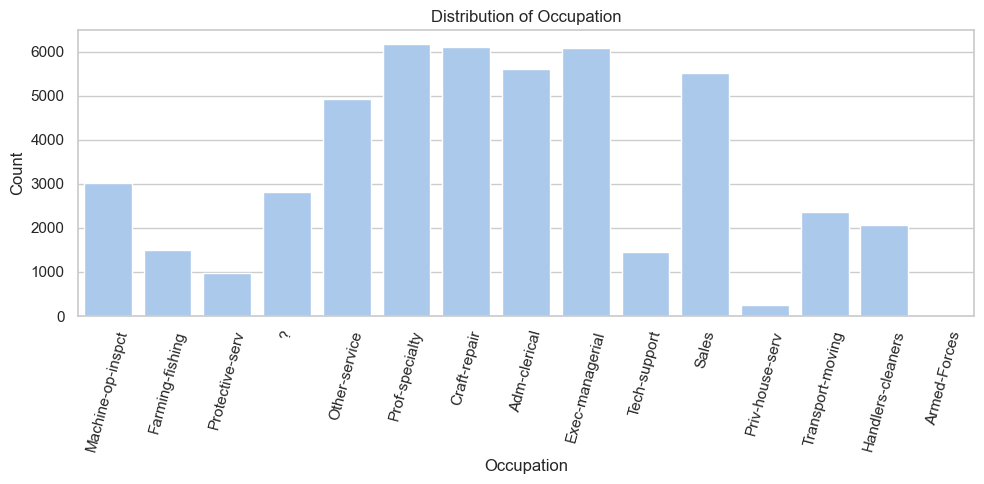

In [254]:
# Show counts of all unique occupations
print(df['occupation'].value_counts())

print('\nmost common',df['occupation'].value_counts().head(1))
plt.figure(figsize=(10, 5))
sns.countplot(x='occupation', data=df, )
plt.xticks(rotation=75)
plt.title("Distribution of Occupation")
plt.xlabel("Occupation")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

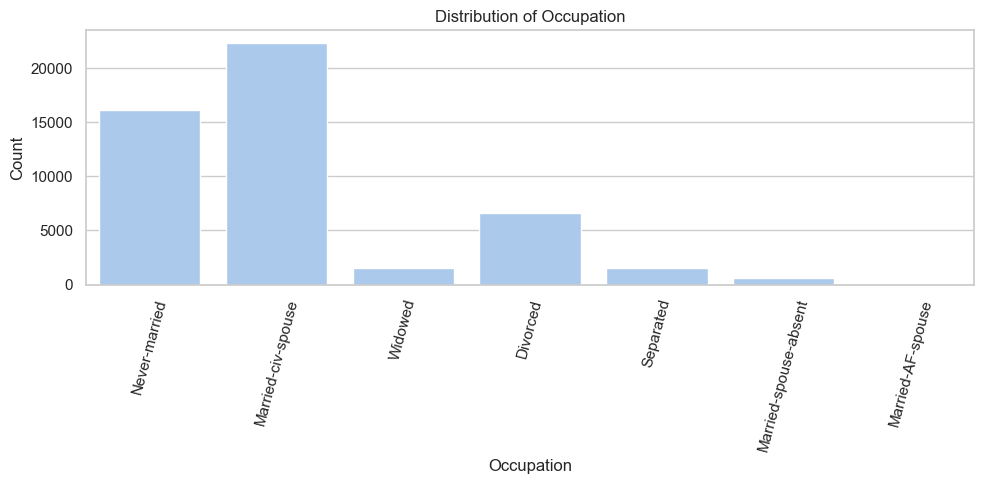

In [255]:

plt.figure(figsize=(10, 5))
sns.countplot(x='marital-status', data=df, )
plt.xticks(rotation=75)
plt.title("Distribution of Occupation")
plt.xlabel("Occupation")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [256]:
df['gender']

0          Male
1          Male
2          Male
3          Male
4        Female
          ...  
48837    Female
48838      Male
48839    Female
48840      Male
48841    Female
Name: gender, Length: 48842, dtype: object

C:\Users\World\AppData\Local\Temp\ipykernel_4776\2608873413.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette="pastel")


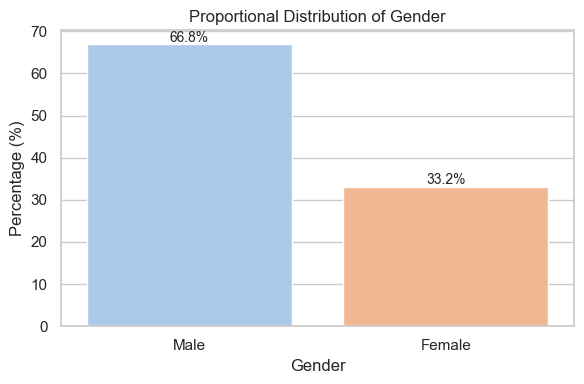

In [257]:
counts = df['gender'].value_counts(normalize=True) * 100  # percentages

plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette="pastel")

# Add percentage labels above bars
for i, val in enumerate(counts.values):
    plt.text(i, val + 0.5, f"{val:.1f}%", ha='center', fontsize=10)

plt.title("Proportional Distribution of Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

race
White                 41762
Black                  4685
Asian-Pac-Islander     1519
Amer-Indian-Eskimo      470
Other                   406
Name: count, dtype: int64


C:\Users\World\AppData\Local\Temp\ipykernel_4776\2923353553.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='race', data=df, order=counts.index, palette='Set2')


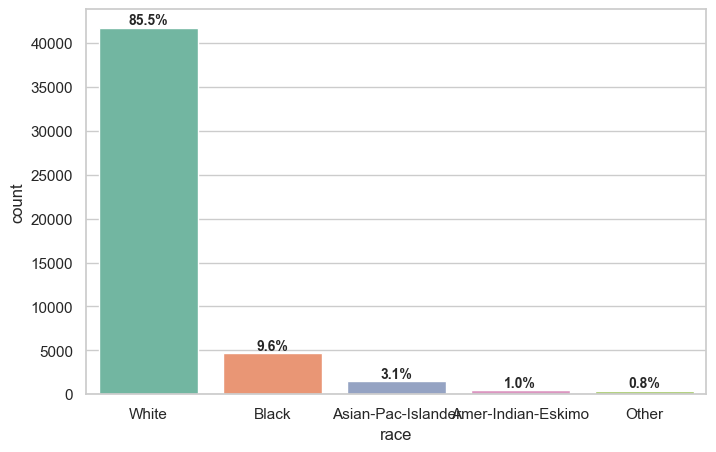

In [258]:
print(df['race'].value_counts())
counts = df['race'].value_counts()
total = len(df)

plt.figure(figsize=(8, 5))
ax = sns.countplot(x='race', data=df, order=counts.index, palette='Set2')

# Add percentages on top of bars
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.1f}%'
    ax.annotate(percentage,
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')


In [259]:
print(df['native-country'].value_counts())
print('\n Most frequently',df['native-country'].value_counts().head(1))


native-country
United-States                 43832
Mexico                          951
?                               857
Philippines                     295
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Guatemala                        88
Poland                           87
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Greece                           49
Nicaragua                        49
Peru         

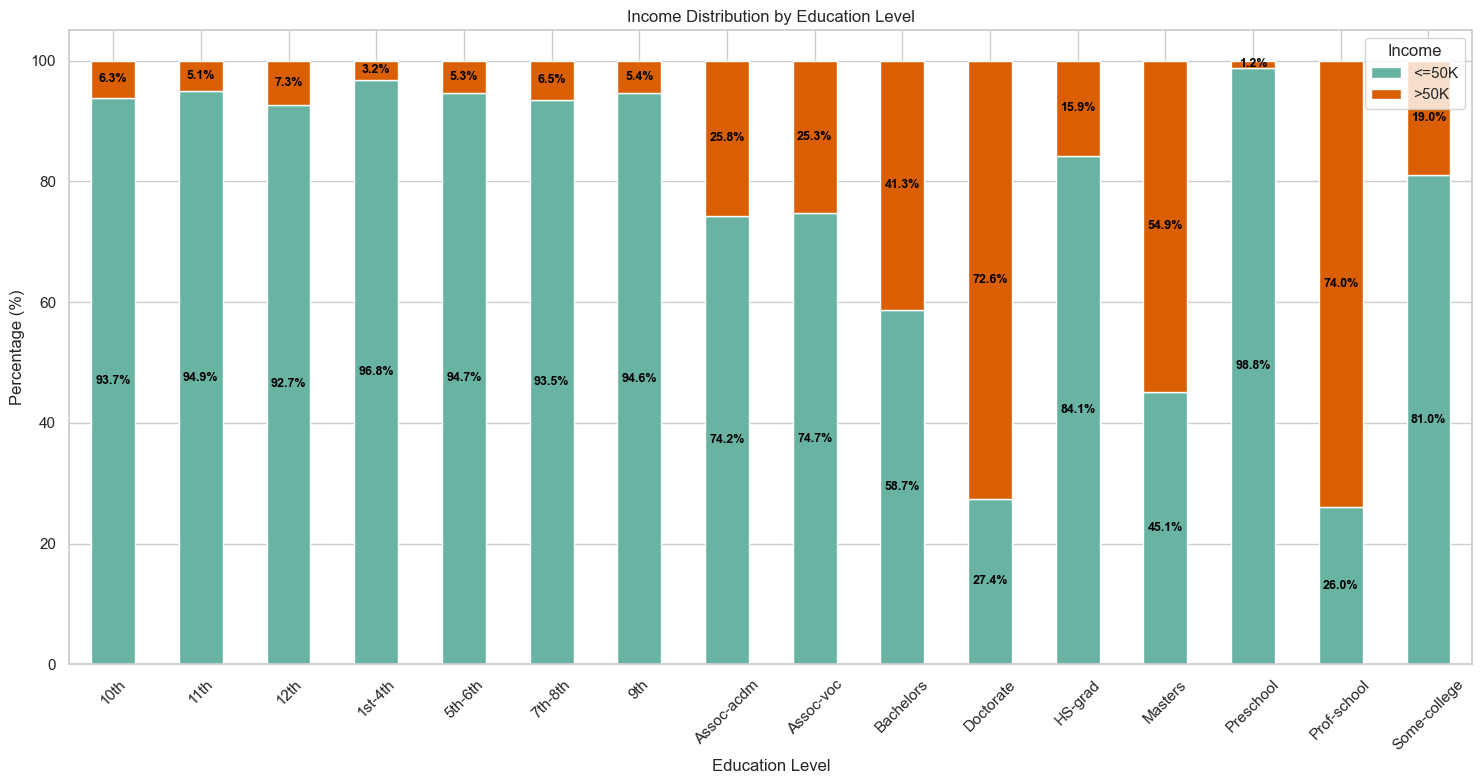

In [260]:
edu_income_percent = pd.crosstab(df["education"], df["income"], normalize="index") * 100

# Plot directly
ax=edu_income_percent.plot(kind="bar", stacked=True, figsize=(15, 8), color=["#69b3a2", "#d95f02"])

plt.title("Income Distribution by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Percentage (%)")
plt.legend(title="Income")
plt.xticks(rotation=45)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",        # format as percentage
        label_type="center", # place inside bar
        fontsize=9,
        color="black",
        fontweight="bold"    # makes it more readable
    )
plt.tight_layout()
plt.show()

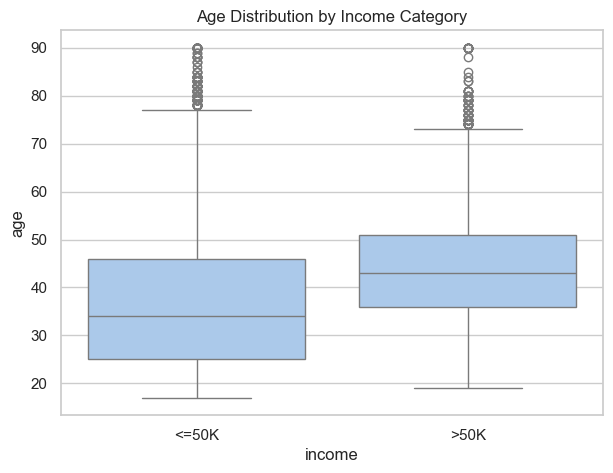

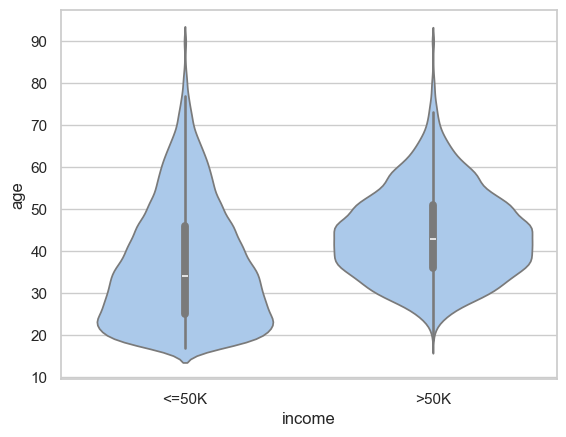

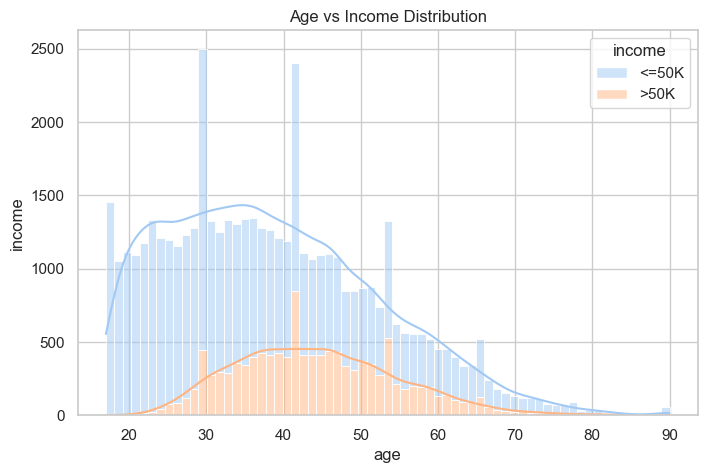

In [261]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="income", y="age", data=df)
plt.title("Age Distribution by Income Category")
plt.show()
sns.violinplot(x="income", y="age", data=df)
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", hue="income", kde=True, multiple="stack")
plt.title("Age vs Income Distribution")
plt.ylabel('income')
plt.show()


In [262]:
age_bins = pd.cut(df["age"], bins=[15,25,35,45,55,65,90])
pd.crosstab(age_bins, df["income"], normalize="index") * 100

income,<=50K,>50K
age,,
"(15, 25]",98.244521,1.755479
"(25, 35]",81.295699,18.704301
"(35, 45]",65.436747,34.563253
"(45, 55]",60.764224,39.235776
"(55, 65]",68.593926,31.406074
"(65, 90]",80.199667,19.800333


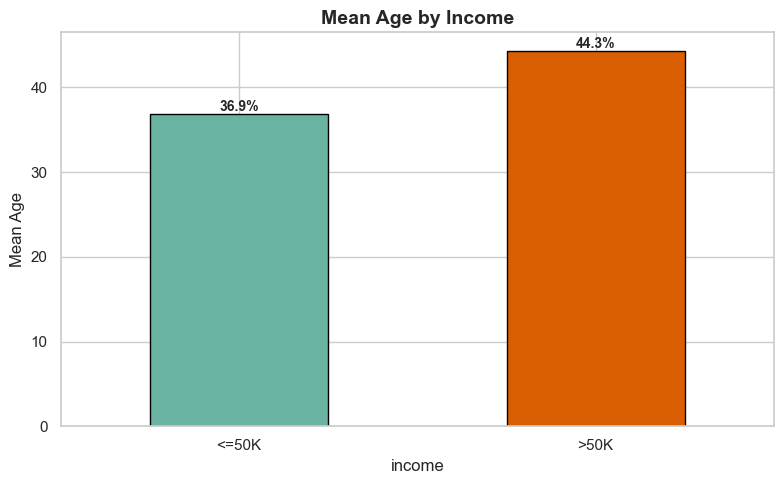

In [263]:
ax = df.groupby("income")["age"].mean().plot(
    kind="bar",
    color=["#69b3a2", "#d95f02"],
    figsize=(8, 5),
    edgecolor="black"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="edge", fontsize=10, fontweight="bold")

plt.title("Mean Age by Income", fontsize=14, fontweight="bold")
plt.ylabel("Mean Age")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



In [264]:
df.groupby('occupation')['income'].value_counts().to_frame()

count
occupation        income       
?                 <=50K    2544
                  >50K      265
Adm-clerical      <=50K    4843
                  >50K      768
Armed-Forces      <=50K      10
                  >50K        5
Craft-repair      <=50K    4729
                  >50K     1383
Exec-managerial   <=50K    3178
                  >50K     2908
Farming-fishing   <=50K    1317
                  >50K      173
Handlers-cleaners <=50K    1934
                  >50K      138
Machine-op-inspct <=50K    2650
                  >50K      372
Other-service     <=50K    4719
                  >50K      204
Priv-house-serv   <=50K     239
                  >50K        3
Prof-specialty    <=50K    3388
                  >50K     2784
Protective-serv   <=50K     675
                  >50K      308
Sales             <=50K    4029
                  >50K     1475
Tech-support      <=50K    1026
                  >50K      420
Transport-moving  <=50K    1874
                  >50K      481

In [265]:
import pandas as pd
import matplotlib.pyplot as plt

# Crosstab to see percentage of people earning <=50K vs >50K in each occupation
occupation_income = pd.crosstab(df["occupation"], df["income"], normalize="index") * 100

# Sort by >50K percentage
occupation_income_sorted = occupation_income.sort_values(by=">50K", ascending=False)

print(occupation_income_sorted)


income                 <=50K       >50K
occupation                             
Exec-managerial    52.218206  47.781794
Prof-specialty     54.893065  45.106935
Armed-Forces       66.666667  33.333333
Protective-serv    68.667345  31.332655
Tech-support       70.954357  29.045643
Sales              73.201308  26.798692
Craft-repair       77.372382  22.627618
Transport-moving   79.575372  20.424628
Adm-clerical       86.312600  13.687400
Machine-op-inspct  87.690271  12.309729
Farming-fishing    88.389262  11.610738
?                  90.566038   9.433962
Handlers-cleaners  93.339768   6.660232
Other-service      95.856185   4.143815
Priv-house-serv    98.760331   1.239669


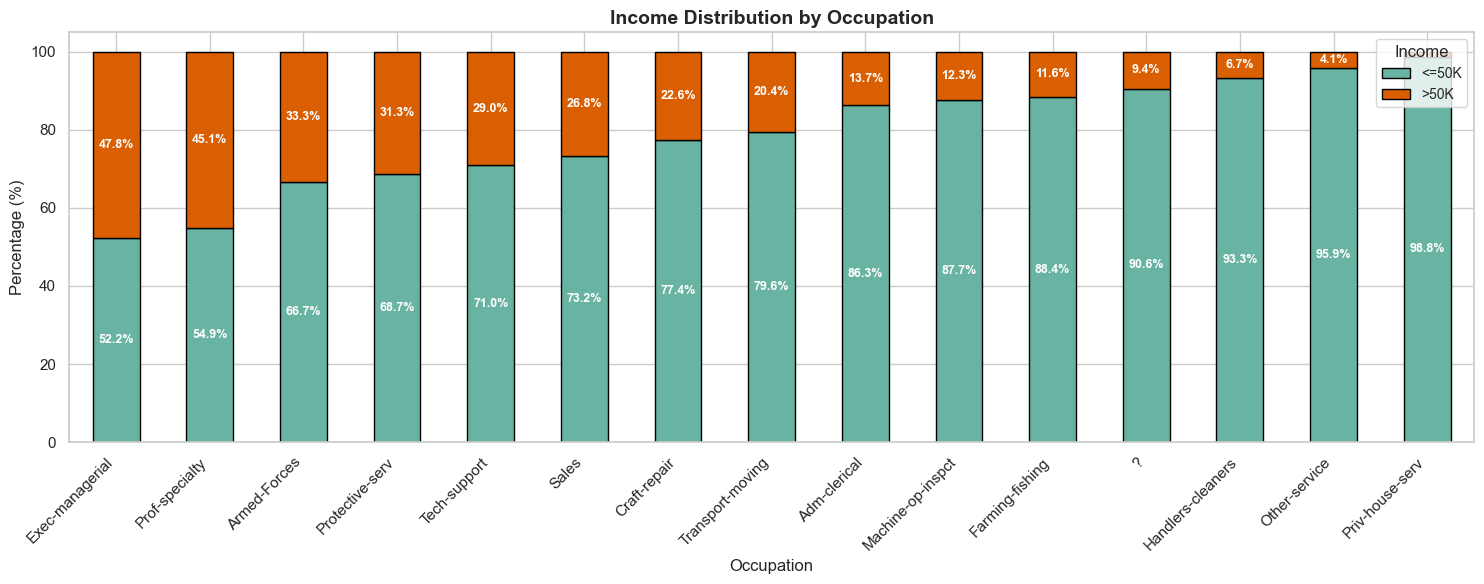

In [266]:
ax = occupation_income_sorted.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 6),
    color=["#69b3a2", "#d95f02"],
    edgecolor="black"  # optional: adds border for clarity
)

plt.title("Income Distribution by Occupation", fontsize=14, fontweight="bold")
plt.xlabel("Occupation")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income", loc="upper right", fontsize=10)

# --- Add percentage labels inside bars ---
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",        # format as percentage
        label_type="center", # place inside bar
        fontsize=9,
        color="white",
        fontweight="bold"    # makes it more readable
    )

plt.tight_layout()
plt.show()


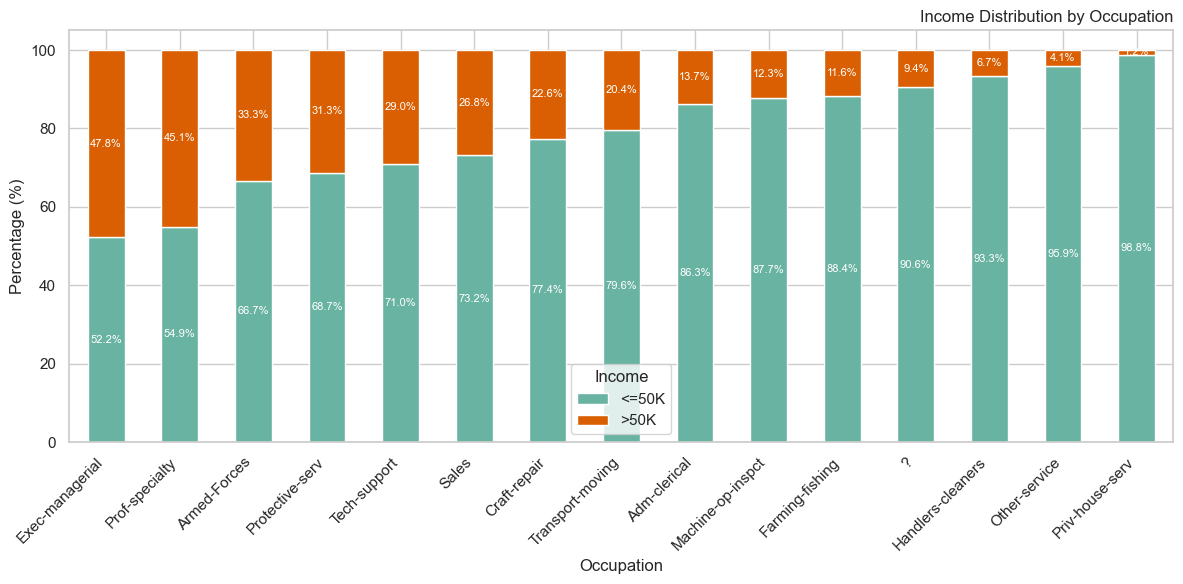

In [267]:
ax = occupation_income_sorted.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["#69b3a2", "#d95f02"]
)

plt.title("Income Distribution by Occupation",loc='right')
plt.xlabel("Occupation")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()

# --- Add percentage labels on bars ---
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', fontsize=8, color='white')

plt.show()

Percentage distribution of income by gender:

income      <=50K       >50K
gender                      
Female  89.074852  10.925148
Male    69.623277  30.376723


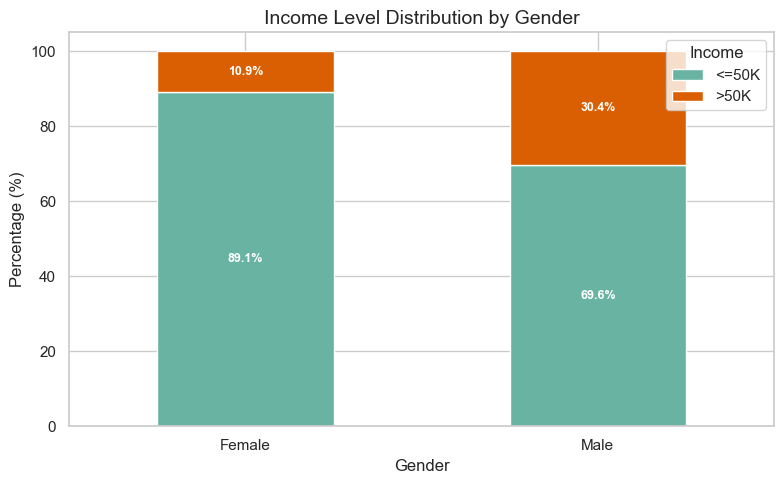

In [268]:
gender_income = pd.crosstab(df['gender'], df['income'], normalize='index') * 100
print("Percentage distribution of income by gender:\n")
print(gender_income)
ax = gender_income.plot(kind='bar', stacked=True, figsize=(8,5), color=["#69b3a2", "#d95f02"])

plt.title("Income Level Distribution by Gender", fontsize=14)
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Income", loc="upper right")

# ✅ Add percentage labels inside bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

income                  <=50K       >50K
race                                    
Amer-Indian-Eskimo  88.297872  11.702128
Asian-Pac-Islander  73.074391  26.925609
Black               87.918890  12.081110
Other               87.684729  12.315271
White               74.601312  25.398688


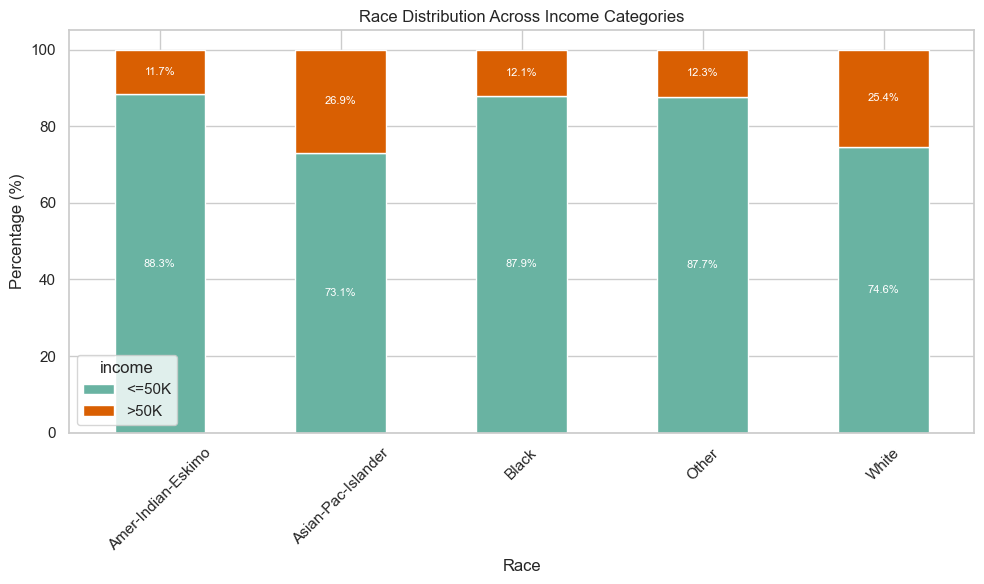

In [269]:
race_income = pd.crosstab(df['race'], df['income'], normalize='index') * 100
print(race_income)

ax = race_income.plot(kind='bar', stacked=True, figsize=(10,6), color=["#69b3a2", "#d95f02"])
plt.title("Race Distribution Across Income Categories")
plt.xlabel("Race")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontsize=8)
plt.tight_layout()
plt.show()

C:\Users\World\AppData\Local\Temp\ipykernel_4776\1363760731.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='hours-per-week', data=df, palette="Set2")


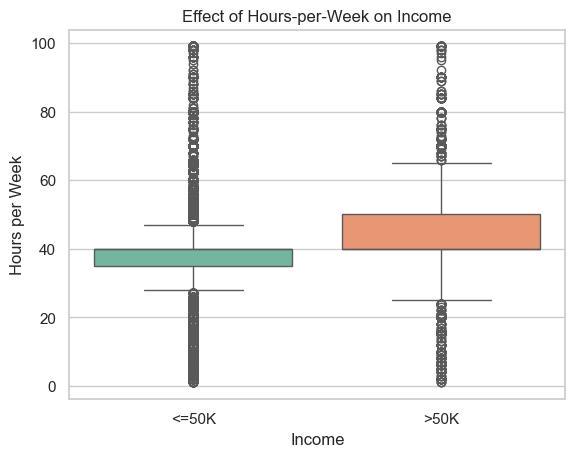

          count       mean        std  min   25%   50%   75%   max
income                                                            
<=50K   37155.0  38.840048  12.356849  1.0  35.0  40.0  40.0  99.0
>50K    11687.0  45.452896  11.091176  1.0  40.0  40.0  50.0  99.0


In [270]:
sns.boxplot(x='income', y='hours-per-week', data=df, palette="Set2")
plt.title("Effect of Hours-per-Week on Income")
plt.ylabel("Hours per Week")
plt.xlabel("Income")
plt.show()

# Optional: Mean comparison
print(df.groupby('income')['hours-per-week'].describe())

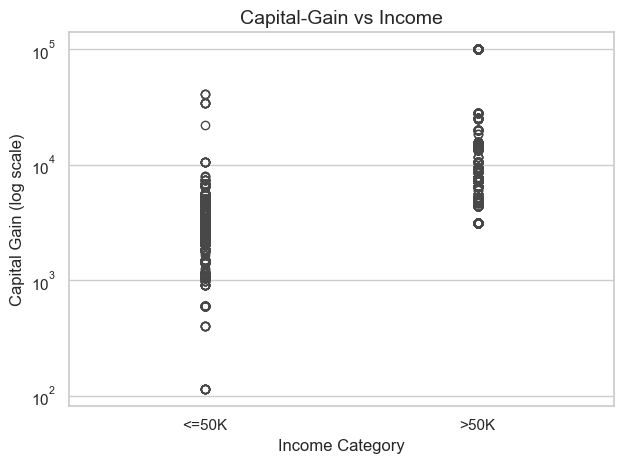

          count         mean           std  min  25%  50%  75%      max
income                                                                 
<=50K   37155.0   147.010308    936.753678  0.0  0.0  0.0  0.0  41310.0
>50K    11687.0  4042.239497  14756.771034  0.0  0.0  0.0  0.0  99999.0


In [271]:
# Boxplot with hue explicitly set
sns.boxplot(x='income', y='capital-gain', hue='income', data=df, palette="Set1", legend=False)
plt.yscale("log")  # Log scale helps visualize skewed data
plt.title("Capital-Gain vs Income", fontsize=14)
plt.ylabel("Capital Gain (log scale)")
plt.xlabel("Income Category")
plt.tight_layout()
plt.show()

# Group statistics
print(df.groupby('income')['capital-gain'].describe())


In [272]:
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")


Total Rows: 48842, Total Columns: 16


In [273]:
print(df.dtypes)


age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
income_binary       int64
dtype: object


In [274]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
print(df[num_cols].describe())


                age        fnlwgt  educational-num  capital-gain  \
count  48842.000000  4.884200e+04     48842.000000  48842.000000   
mean      38.643585  1.896641e+05        10.078089   1079.067626   
std       13.710510  1.056040e+05         2.570973   7452.019058   
min       17.000000  1.228500e+04         1.000000      0.000000   
25%       28.000000  1.175505e+05         9.000000      0.000000   
50%       37.000000  1.781445e+05        10.000000      0.000000   
75%       48.000000  2.376420e+05        12.000000      0.000000   
max       90.000000  1.490400e+06        16.000000  99999.000000   

       capital-loss  hours-per-week  income_binary  
count  48842.000000    48842.000000   48842.000000  
mean      87.502314       40.422382       0.239282  
std      403.004552       12.391444       0.426649  
min        0.000000        1.000000       0.000000  
25%        0.000000       40.000000       0.000000  
50%        0.000000       40.000000       0.000000  
75%        0.000

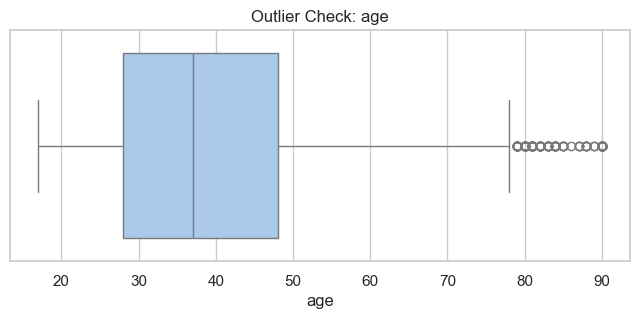

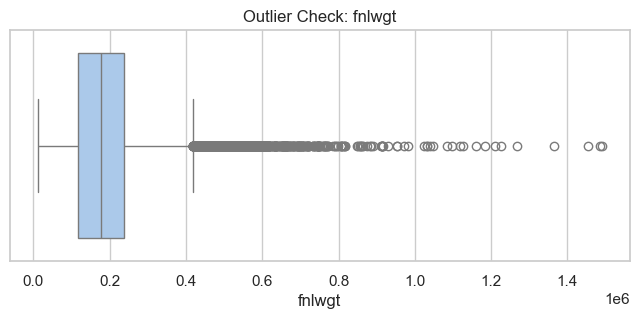

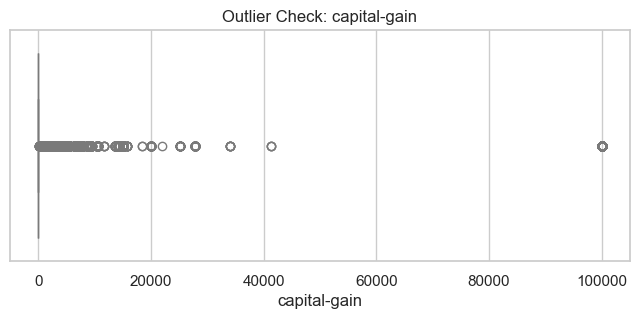

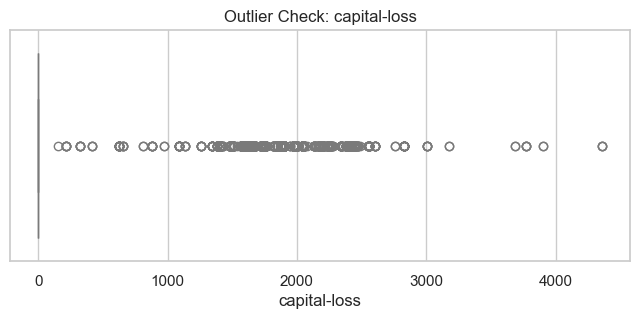

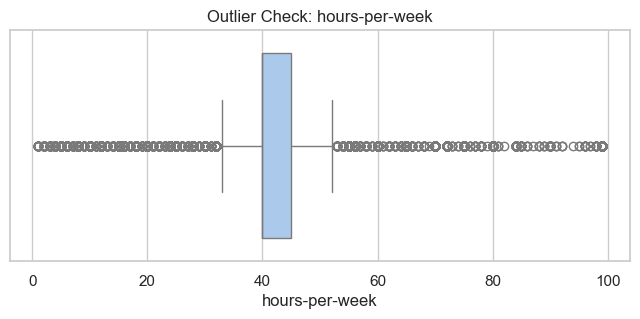

In [275]:
for col in ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Check: {col}")
    plt.show()


In [276]:
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"\nTop 5 categories in {col}:\n")
    print(df[col].value_counts().head(5))



Top 5 categories in workclass:

workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
?                    2799
State-gov            1981
Name: count, dtype: int64

Top 5 categories in education:

education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
Name: count, dtype: int64

Top 5 categories in marital-status:

marital-status
Married-civ-spouse    22379
Never-married         16117
Divorced               6633
Separated              1530
Widowed                1518
Name: count, dtype: int64

Top 5 categories in occupation:

occupation
Prof-specialty     6172
Craft-repair       6112
Exec-managerial    6086
Adm-clerical       5611
Sales              5504
Name: count, dtype: int64

Top 5 categories in relationship:

relationship
Husband          19716
Not-in-family    12583
Own-child         7581
Unmarried         5125
Wife              2331
Name: count, dtype: int64

Top 5 categories in r

In [277]:
print(f"Unique Countries: {df['native-country'].nunique()}")
print(df['native-country'].value_counts())


Unique Countries: 42
native-country
United-States                 43832
Mexico                          951
?                               857
Philippines                     295
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Guatemala                        88
Poland                           87
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Greece                           49
Nicaragua                   

income
<=50K    36.872184
>50K     44.275178
Name: age, dtype: float64


C:\Users\World\AppData\Local\Temp\ipykernel_4776\2140163548.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='income', y='age', data=df, ci=None, palette="coolwarm")
C:\Users\World\AppData\Local\Temp\ipykernel_4776\2140163548.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='income', y='age', data=df, ci=None, palette="coolwarm")


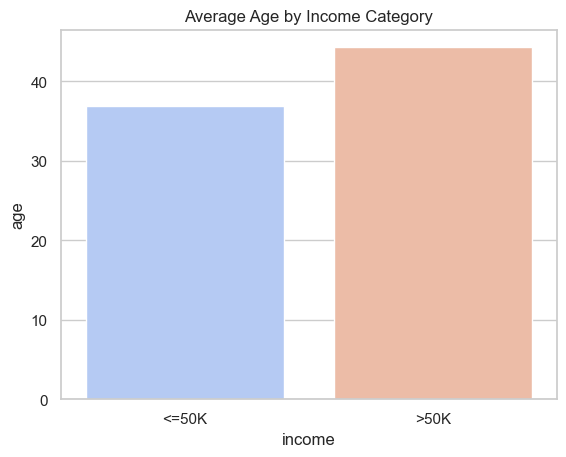

In [278]:
print(df.groupby('income')['age'].mean())
sns.barplot(x='income', y='age', data=df, ci=None, palette="coolwarm")
plt.title("Average Age by Income Category")
plt.show()


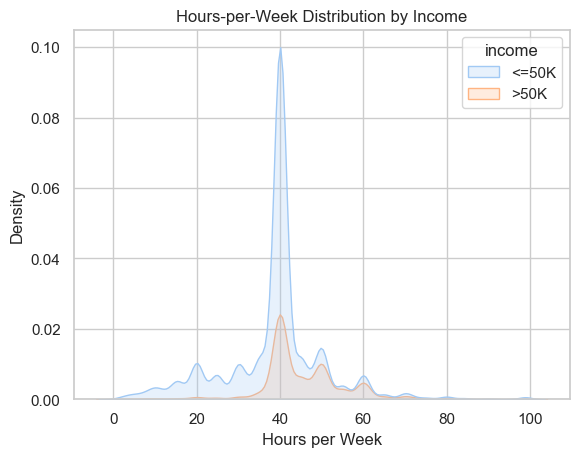

In [279]:
sns.kdeplot(data=df, x='hours-per-week', hue='income', fill=True)
plt.title("Hours-per-Week Distribution by Income")
plt.xlabel("Hours per Week")
plt.show()


income                 <=50K       >50K
occupation                             
Exec-managerial    52.218206  47.781794
Prof-specialty     54.893065  45.106935
Armed-Forces       66.666667  33.333333
Protective-serv    68.667345  31.332655
Tech-support       70.954357  29.045643
Sales              73.201308  26.798692
Craft-repair       77.372382  22.627618
Transport-moving   79.575372  20.424628
Adm-clerical       86.312600  13.687400
Machine-op-inspct  87.690271  12.309729
Farming-fishing    88.389262  11.610738
?                  90.566038   9.433962
Handlers-cleaners  93.339768   6.660232
Other-service      95.856185   4.143815
Priv-house-serv    98.760331   1.239669


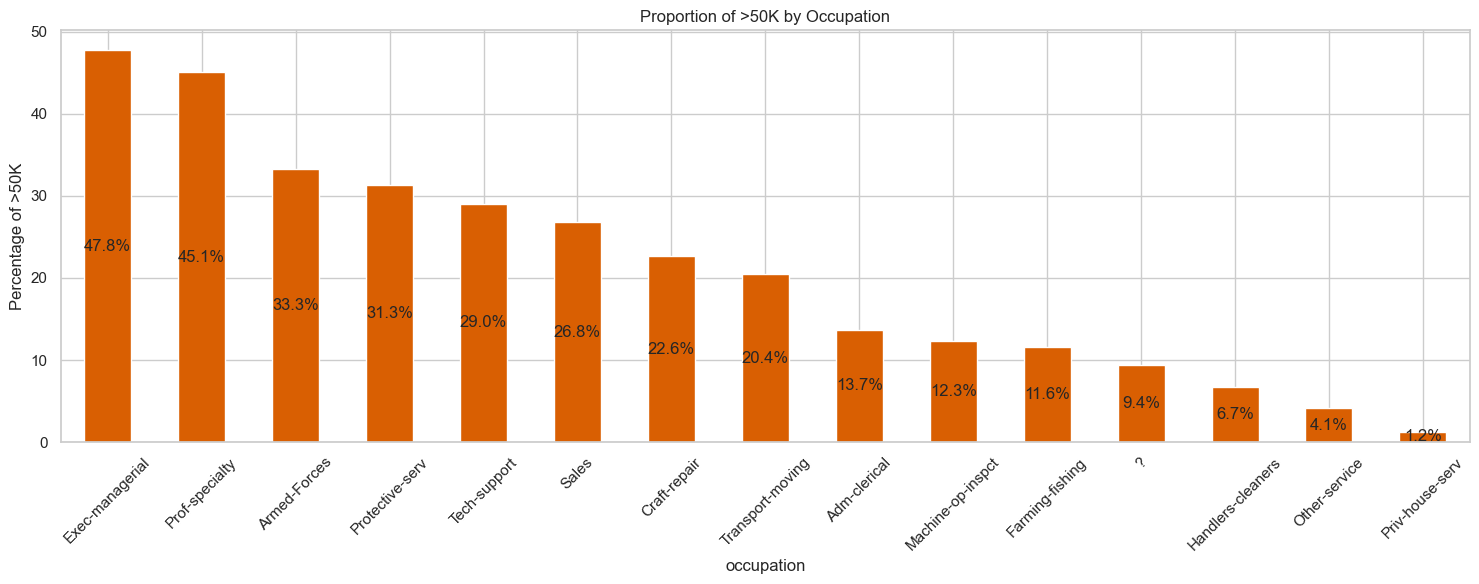

In [280]:
occ_income = pd.crosstab(df['occupation'], df['income'], normalize='index') * 100
occ_income_sorted = occ_income.sort_values(by='>50K', ascending=False)
print(occ_income_sorted)

ax = occ_income_sorted['>50K'].plot(kind='bar', figsize=(15,6), color='#d95f02')
plt.title("Proportion of >50K by Occupation")
plt.ylabel("Percentage of >50K")
plt.xticks(rotation=45)
# Add percentage labels inside the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type='center')

plt.tight_layout()
plt.show()


gender               Female       Male
workclass                             
?                 45.373348  54.626652
Federal-gov       31.564246  68.435754
Local-gov         40.114796  59.885204
Never-worked      30.000000  70.000000
Private           34.209284  65.790716
Self-emp-inc      12.448378  87.551622
Self-emp-not-inc  16.286898  83.713102
State-gov         38.515901  61.484099
Without-pay       33.333333  66.666667


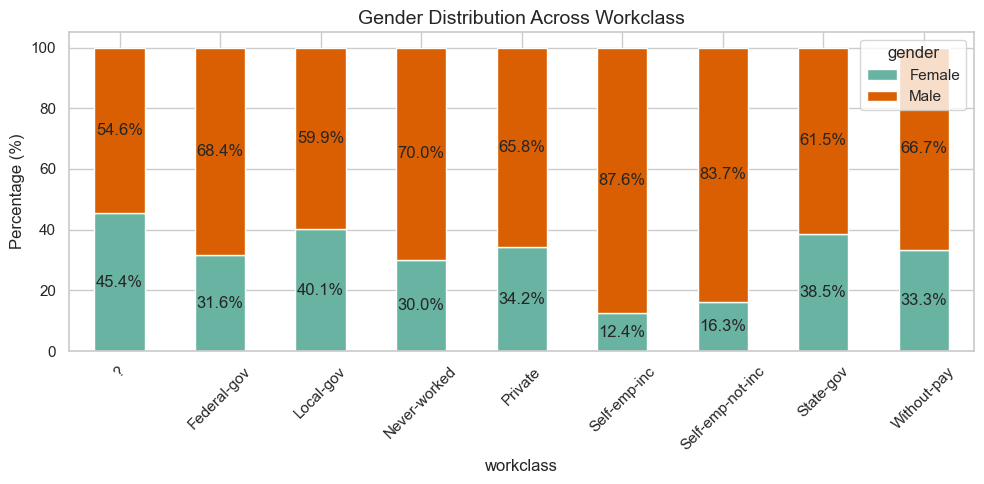

In [281]:
# Crosstab: percentage distribution of gender within each workclass
gender_workclass = pd.crosstab(df['workclass'], df['gender'], normalize='index') * 100
print(gender_workclass)

# Plot stacked bar chart
ax = gender_workclass.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color=["#69b3a2", "#d95f02"]
)

plt.title("Gender Distribution Across Workclass", fontsize=14)
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()

# Add percentage labels inside the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type='center')

plt.show()

In [282]:
for col in ["workclass", "occupation", "native-country"]:
    missing_count = (df[col] == "?").sum()
    missing_percent = (missing_count / len(df)) * 100
    print(f"{col}: {missing_count} missing ({missing_percent:.2f}%)")


workclass: 2799 missing (5.73%)
occupation: 2809 missing (5.75%)
native-country: 857 missing (1.75%)


In [283]:
for col in ["workclass", "occupation", "native-country"]:
    df[col] = df[col].replace("?", "Unknown")


In [284]:
for col in ["workclass", "occupation", "native-country"]:
    missing_count = (df[col] == "?").sum()
    missing_percent = (missing_count / len(df)) * 100
    print(f"{col}: {missing_count} missing ({missing_percent:.2f}%)")


workclass: 0 missing (0.00%)
occupation: 0 missing (0.00%)
native-country: 0 missing (0.00%)


In [285]:
# Check unique values in native-country
print(df['native-country'].unique())
print('\n\n')

# Or get value counts for a better look
print(df['native-country'].value_counts())


['United-States' 'Unknown' 'Peru' 'Guatemala' 'Mexico'
 'Dominican-Republic' 'Ireland' 'Germany' 'Philippines' 'Thailand' 'Haiti'
 'El-Salvador' 'Puerto-Rico' 'Vietnam' 'South' 'Columbia' 'Japan' 'India'
 'Cambodia' 'Poland' 'Laos' 'England' 'Cuba' 'Taiwan' 'Italy' 'Canada'
 'Portugal' 'China' 'Nicaragua' 'Honduras' 'Iran' 'Scotland' 'Jamaica'
 'Ecuador' 'Yugoslavia' 'Hungary' 'Hong' 'Greece' 'Trinadad&Tobago'
 'Outlying-US(Guam-USVI-etc)' 'France' 'Holand-Netherlands']



native-country
United-States                 43832
Mexico                          951
Unknown                         857
Philippines                     295
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Ita

In [286]:
print("\nAfter Imputation Missing Values Check:")
for col in ["workclass", "occupation", "native-country"]:
    print(f"{col}: {(df[col]=='Unknown').sum()} replaced with 'Unknown'")




After Imputation Missing Values Check:
workclass: 2799 replaced with 'Unknown'
occupation: 2809 replaced with 'Unknown'
native-country: 857 replaced with 'Unknown'


In [287]:
# Show unique categories BEFORE cleaning
print("\n===== Unique Categories in native-country (Before Cleaning) =====")
before_clean = pd.DataFrame({"native-country": sorted(df["native-country"].dropna().unique())})
print(before_clean)

# Normalize: strip spaces + lowercase
df["native-country"] = df["native-country"].str.strip().str.title()

# Show unique categories AFTER cleaning
print("\n===== Unique Categories in native-country (After Cleaning) =====")
after_clean = pd.DataFrame({"native-country": sorted(df["native-country"].dropna().unique())})
print(after_clean)

# Show value counts as a dataset (Safe version)
print("\n===== Value Counts (Sorted by Country Name) =====")
value_counts_df = (
    df["native-country"]
    .value_counts()
    .rename_axis("native-country")  # <-- Renames index
    .reset_index(name="count")      # <-- Converts to columns
    .sort_values(by="native-country")  # Sort alphabetically
    .reset_index(drop=True)
)
print(value_counts_df)



===== Unique Categories in native-country (Before Cleaning) =====
                native-country
0                     Cambodia
1                       Canada
2                        China
3                     Columbia
4                         Cuba
5           Dominican-Republic
6                      Ecuador
7                  El-Salvador
8                      England
9                       France
10                     Germany
11                      Greece
12                   Guatemala
13                       Haiti
14          Holand-Netherlands
15                    Honduras
16                        Hong
17                     Hungary
18                       India
19                        Iran
20                     Ireland
21                       Italy
22                     Jamaica
23                       Japan
24                        Laos
25                      Mexico
26                   Nicaragua
27  Outlying-US(Guam-USVI-etc)
28                        Peru
29 

In [288]:
df["education-num"] = df["education"].factorize()[0]

# Now check correlation
edu_corr = df["education"].factorize()[0]
print("\nCorrelation between education & education-num:",
      np.corrcoef(edu_corr, df["education-num"])[0, 1])



Correlation between education & education-num: 0.9999999999999999


In [289]:
print("\n===== Zero / Extreme Values Check =====")
for col in ["age", "capital-gain", "capital-loss", "hours-per-week"]:
    print(f"{col} - Min: {df[col].min()}, Max: {df[col].max()}")
# Check if capital-gain has suspicious placeholder like 99999
print("\nRows with capital-gain=99999:\n", df[df["capital-gain"] == 99999])
    



===== Zero / Extreme Values Check =====
age - Min: 17, Max: 90
capital-gain - Min: 0, Max: 99999
capital-loss - Min: 0, Max: 4356
hours-per-week - Min: 1, Max: 99

Rows with capital-gain=99999:
        age         workclass  fnlwgt    education  educational-num  \
83      44      Self-emp-inc  223881      HS-grad                9   
346     39           Private  198654      HS-grad                9   
357     50  Self-emp-not-inc  165001  Prof-school               15   
418     54      Self-emp-inc  159219  Prof-school               15   
692     41           Private  191547      Masters               14   
...    ...               ...     ...          ...              ...   
48109   47           Private  155664      Masters               14   
48253   43      Self-emp-inc   62026  Prof-school               15   
48371   66           Private  115498    Bachelors               13   
48519   47           Private  294913  Prof-school               15   
48799   57         Local-gov  1104

In [290]:
missing_summary = (df == "Unknown").sum()
print("\n===== Missing Value Summary =====")
print(missing_summary[missing_summary > 0])



===== Missing Value Summary =====
workclass         2799
occupation        2809
native-country     857
dtype: int64


In [291]:
duplicates = df.duplicated().sum()
print(f"\nDuplicate Rows Found: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicates dropped.")


Duplicate Rows Found: 52
Duplicates dropped.


In [292]:
print("\nUnique Values in workclass:\n", df["workclass"].unique())
print("\nUnique Values in occupation:\n", df["occupation"].unique())



Unique Values in workclass:
 ['Private' 'Local-gov' 'Unknown' 'Self-emp-not-inc' 'Federal-gov'
 'State-gov' 'Self-emp-inc' 'Without-pay' 'Never-worked']

Unique Values in occupation:
 ['Machine-op-inspct' 'Farming-fishing' 'Protective-serv' 'Unknown'
 'Other-service' 'Prof-specialty' 'Craft-repair' 'Adm-clerical'
 'Exec-managerial' 'Tech-support' 'Sales' 'Priv-house-serv'
 'Transport-moving' 'Handlers-cleaners' 'Armed-Forces']


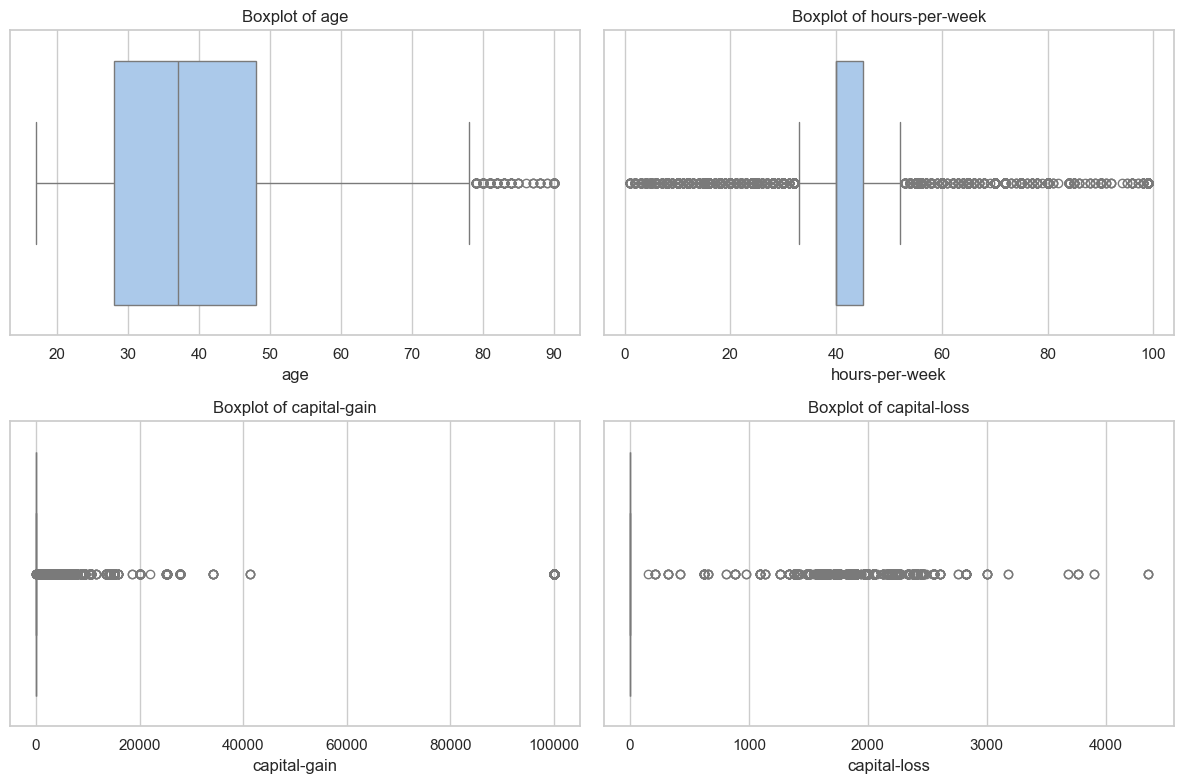

In [293]:
numeric_cols = ["age", "hours-per-week", "capital-gain", "capital-loss"]
plt.figure(figsize=(12, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()


In [294]:
invalid_age = df[df["age"] <= 0]
print(f"\nInvalid Age Rows: {len(invalid_age)}")
if not invalid_age.empty:
    print(invalid_age)



Invalid Age Rows: 0


In [295]:
print("\nCorrelation of fnlwgt with income:")
print(df[["fnlwgt", "education-num"]].corr())  # usually fnlwgt not predictive -> candidate for removal



Correlation of fnlwgt with income:
                 fnlwgt  education-num
fnlwgt         1.000000       0.004816
education-num  0.004816       1.000000


In [296]:
df["workclass"] = df["workclass"].str.strip()
df["occupation"] = df["occupation"].str.strip()

print("\nFinal Cleaned Dataset Info:")
print(df.info())


Final Cleaned Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 48790 entries, 0 to 48841
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48790 non-null  int64 
 1   workclass        48790 non-null  object
 2   fnlwgt           48790 non-null  int64 
 3   education        48790 non-null  object
 4   educational-num  48790 non-null  int64 
 5   marital-status   48790 non-null  object
 6   occupation       48790 non-null  object
 7   relationship     48790 non-null  object
 8   race             48790 non-null  object
 9   gender           48790 non-null  object
 10  capital-gain     48790 non-null  int64 
 11  capital-loss     48790 non-null  int64 
 12  hours-per-week   48790 non-null  int64 
 13  native-country   48790 non-null  object
 14  income           48790 non-null  object
 15  income_binary    48790 non-null  int64 
 16  education-num    48790 non-null  int64 
dtypes: int6

C:\Users\World\AppData\Local\Temp\ipykernel_4776\2430206745.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["workclass"] = df["workclass"].str.strip()
C:\Users\World\AppData\Local\Temp\ipykernel_4776\2430206745.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["occupation"] = df["occupation"].str.strip()


In [297]:
dummies = pd.get_dummies(df[["workclass", "occupation"]], drop_first=True)

df = pd.concat([df, dummies], axis=1)

print(df.head())

   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802          11th                7       Never-married   
1   38    Private   89814       HS-grad                9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm               12  Married-civ-spouse   
3   44    Private  160323  Some-college               10  Married-civ-spouse   
4   18    Unknown  103497  Some-college               10       Never-married   

          occupation relationship   race  gender  ...  \
0  Machine-op-inspct    Own-child  Black    Male  ...   
1    Farming-fishing      Husband  White    Male  ...   
2    Protective-serv      Husband  White    Male  ...   
3  Machine-op-inspct      Husband  Black    Male  ...   
4            Unknown    Own-child  White  Female  ...   

   occupation_Handlers-cleaners  occupation_Machine-op-inspct  \
0                         False                          True   
1                         False               

In [298]:
df["gender"] = df["gender"].map({"Male": 0, "Female": 1,'male':0,'female':1})
df

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,...,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,occupation_Unknown
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,0,...,False,True,False,False,False,False,False,False,False,False
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,0,...,False,False,False,False,False,False,False,False,False,False
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,0,...,False,False,False,False,False,True,False,False,False,False
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,0,...,False,True,False,False,False,False,False,False,False,False
4,18,Unknown,103497,Some-college,10,Never-married,Unknown,Own-child,White,1,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,1,...,False,False,False,False,False,False,False,True,False,False
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,0,...,False,True,False,False,False,False,False,False,False,False
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,1,...,False,False,False,False,False,False,False,False,False,False
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,0,...,False,False,False,False,False,False,False,False,False,False


In [299]:
top_countries = df["native-country"].value_counts().nlargest(5).index
df["native-country"] = df["native-country"].apply(lambda x: x if x in top_countries else "Other")
df['native-country']

0        United-States
1        United-States
2        United-States
3        United-States
4        United-States
             ...      
48837    United-States
48838    United-States
48839    United-States
48840    United-States
48841    United-States
Name: native-country, Length: 48790, dtype: object

In [300]:
bins = [0, 25, 45, 65, 100]
labels = ["Young", "Mid-age", "Senior", "Retired"]
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)
df

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,...,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,occupation_Unknown,age_group
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,0,...,True,False,False,False,False,False,False,False,False,Young
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,0,...,False,False,False,False,False,False,False,False,False,Mid-age
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,0,...,False,False,False,False,True,False,False,False,False,Mid-age
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,0,...,True,False,False,False,False,False,False,False,False,Mid-age
4,18,Unknown,103497,Some-college,10,Never-married,Unknown,Own-child,White,1,...,False,False,False,False,False,False,False,False,True,Young
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,1,...,False,False,False,False,False,False,True,False,False,Mid-age
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,0,...,True,False,False,False,False,False,False,False,False,Mid-age
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,1,...,False,False,False,False,False,False,False,False,False,Senior
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,0,...,False,False,False,False,False,False,False,False,False,Young


In [301]:
df["has_capital_gain"] = (df["capital-gain"] > 0).astype(int)
df["has_capital_loss"] = (df["capital-loss"] > 0).astype(int)
df

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,...,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,occupation_Unknown,age_group,has_capital_gain,has_capital_loss
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,0,...,False,False,False,False,False,False,False,Young,0,0
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,0,...,False,False,False,False,False,False,False,Mid-age,0,0
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,0,...,False,False,True,False,False,False,False,Mid-age,0,0
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,0,...,False,False,False,False,False,False,False,Mid-age,1,0
4,18,Unknown,103497,Some-college,10,Never-married,Unknown,Own-child,White,1,...,False,False,False,False,False,False,True,Young,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,1,...,False,False,False,False,True,False,False,Mid-age,0,0
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,0,...,False,False,False,False,False,False,False,Mid-age,0,0
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,1,...,False,False,False,False,False,False,False,Senior,0,0
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,0,...,False,False,False,False,False,False,False,Young,0,0


In [302]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[["age", "hours-per-week", "capital-gain", "capital-loss"]] = scaler.fit_transform(
    df[["age", "hours-per-week", "capital-gain", "capital-loss"]]
)
df

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,...,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,occupation_Unknown,age_group,has_capital_gain,has_capital_loss
0,-0.995947,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,0,...,False,False,False,False,False,False,False,Young,0,0
1,-0.047620,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,0,...,False,False,False,False,False,False,False,Mid-age,0,0
2,-0.777103,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,0,...,False,False,True,False,False,False,False,Mid-age,0,0
3,0.390069,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,0,...,False,False,False,False,False,False,False,Mid-age,1,0
4,-1.506585,Unknown,103497,Some-college,10,Never-married,Unknown,Own-child,White,1,...,False,False,False,False,False,False,True,Young,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,-0.850051,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,1,...,False,False,False,False,True,False,False,Mid-age,0,0
48838,0.098276,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,0,...,False,False,False,False,False,False,False,Mid-age,0,0
48839,1.411344,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,1,...,False,False,False,False,False,False,False,Senior,0,0
48840,-1.214792,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,0,...,False,False,False,False,False,False,False,Young,0,0


In [303]:
df["native-country"] = df["native-country"].apply(lambda x: x if x == "United-States" else "Other")
df

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,...,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,occupation_Unknown,age_group,has_capital_gain,has_capital_loss
0,-0.995947,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,0,...,False,False,False,False,False,False,False,Young,0,0
1,-0.047620,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,0,...,False,False,False,False,False,False,False,Mid-age,0,0
2,-0.777103,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,0,...,False,False,True,False,False,False,False,Mid-age,0,0
3,0.390069,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,0,...,False,False,False,False,False,False,False,Mid-age,1,0
4,-1.506585,Unknown,103497,Some-college,10,Never-married,Unknown,Own-child,White,1,...,False,False,False,False,False,False,True,Young,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,-0.850051,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,1,...,False,False,False,False,True,False,False,Mid-age,0,0
48838,0.098276,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,0,...,False,False,False,False,False,False,False,Mid-age,0,0
48839,1.411344,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,1,...,False,False,False,False,False,False,False,Senior,0,0
48840,-1.214792,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,0,...,False,False,False,False,False,False,False,Young,0,0


In [304]:
edu_order = {
    "Preschool": 1, "1st-4th": 2, "5th-6th": 3, "7th-8th": 4, 
    "9th": 5, "10th": 6, "11th": 7, "12th": 8,
    "HS-grad": 9, "Some-college": 10, "Assoc-acdm": 11,
    "Assoc-voc": 12, "Bachelors": 13, "Masters": 14,
    "Prof-school": 15, "Doctorate": 16
}

# Create a new numeric column
df["education-num"] = df["education"].map(edu_order)

print(df[["education", "education-num"]].head(10))


      education  education-num
0          11th              7
1       HS-grad              9
2    Assoc-acdm             11
3  Some-college             10
4  Some-college             10
5          10th              6
6       HS-grad              9
7   Prof-school             15
8  Some-college             10
9       7th-8th              4


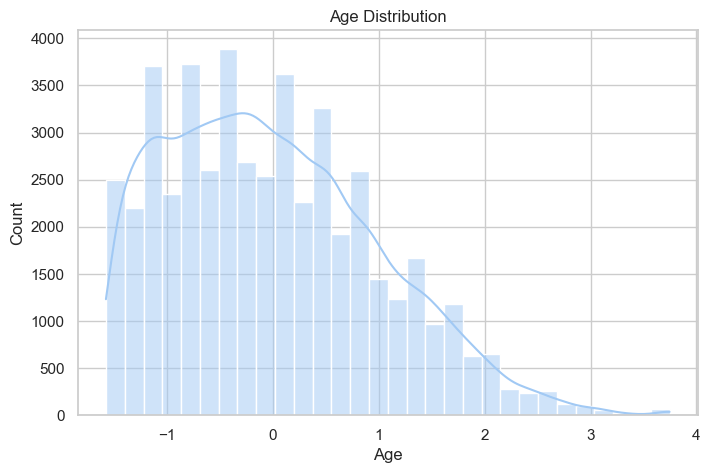

In [305]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()


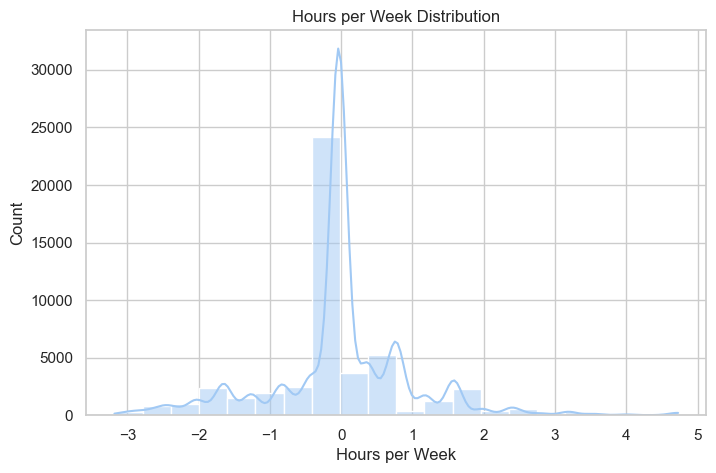

In [306]:
plt.figure(figsize=(8, 5))
sns.histplot(df['hours-per-week'], bins=20, kde=True)
plt.title("Hours per Week Distribution")
plt.xlabel("Hours per Week")
plt.ylabel("Count")
plt.show()


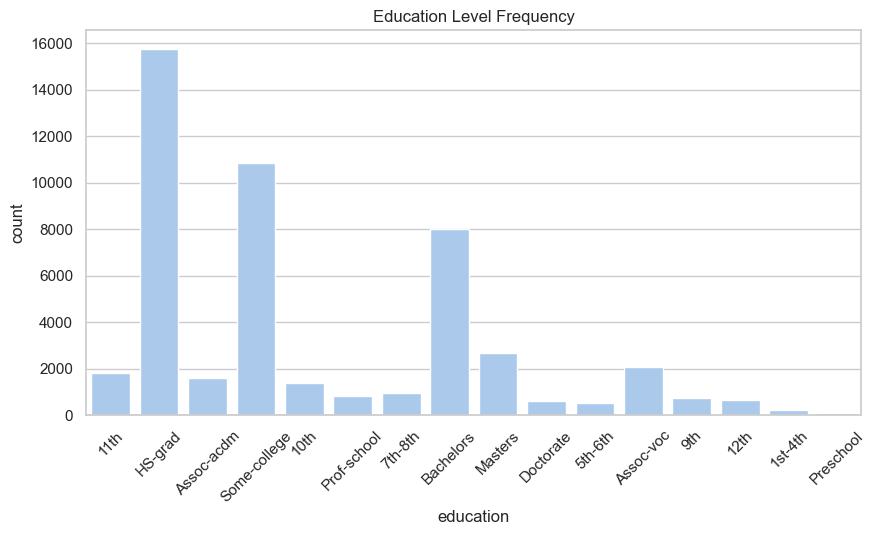

In [307]:
plt.figure(figsize=(10, 5))
sns.countplot(x='education', data=df, )
plt.title("Education Level Frequency")
plt.xticks(rotation=45)
plt.show()


In [308]:
df['workclass']

0             Private
1             Private
2           Local-gov
3             Private
4             Unknown
             ...     
48837         Private
48838         Private
48839         Private
48840         Private
48841    Self-emp-inc
Name: workclass, Length: 48790, dtype: object

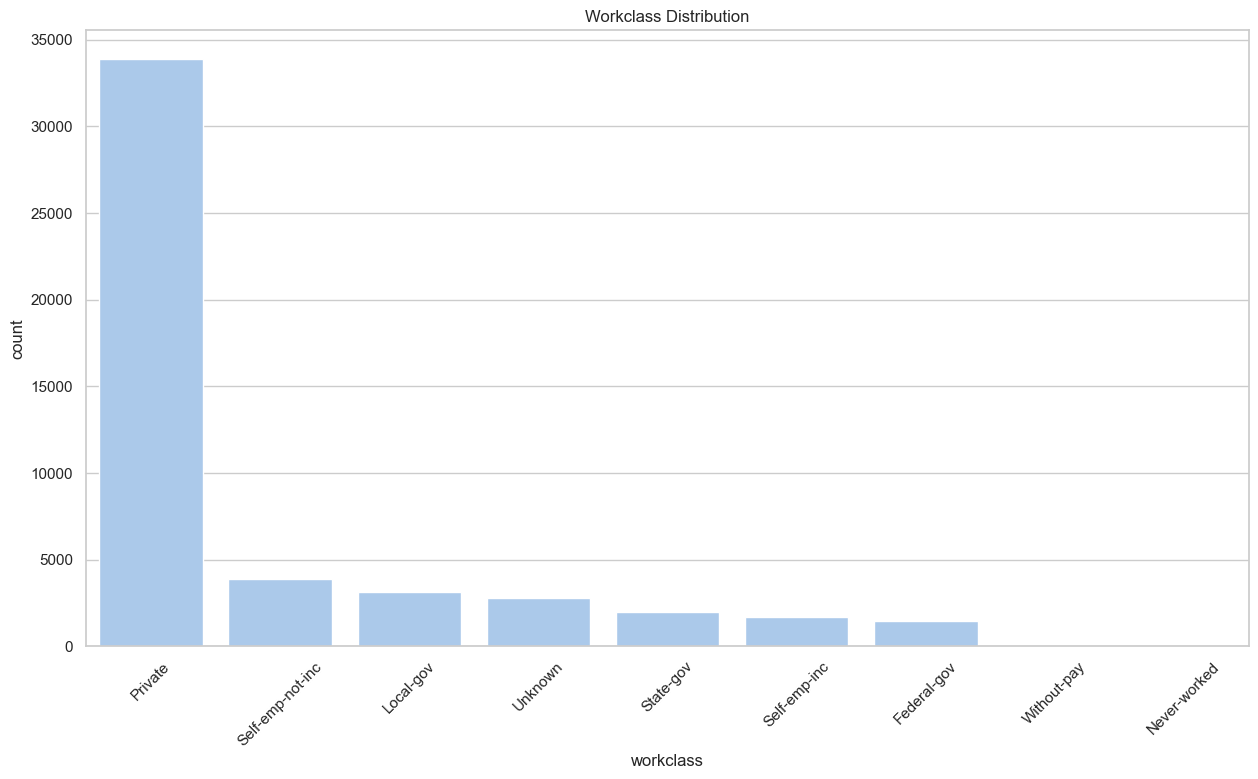

In [309]:
plt.figure(figsize=(15, 8))
sns.countplot(x='workclass', data=df, order=df['workclass'].value_counts().index)
plt.title("Workclass Distribution")
plt.xticks(rotation=45)
plt.show()


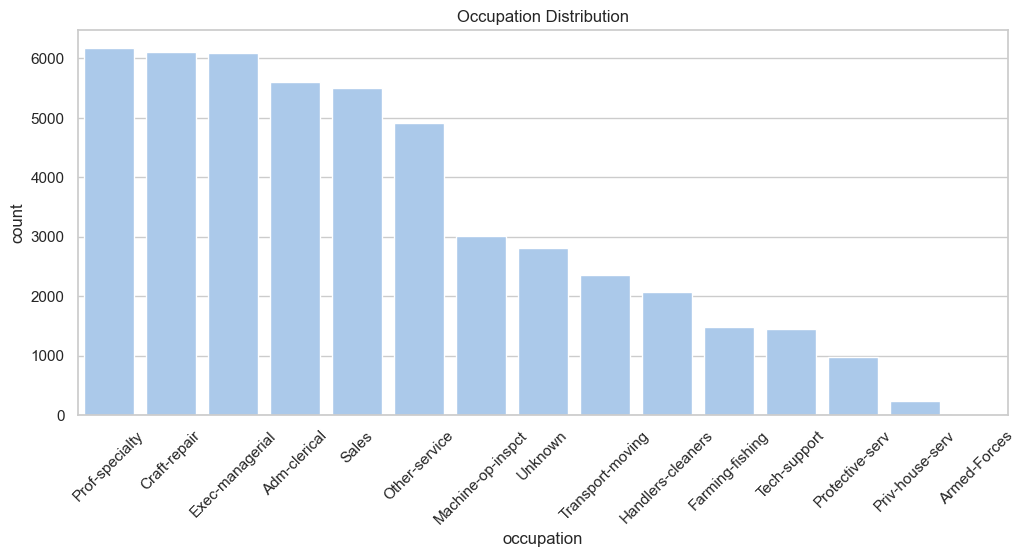

In [310]:
plt.figure(figsize=(12, 5))
sns.countplot(x='occupation', data=df, order=df['occupation'].value_counts().index)
plt.title("Occupation Distribution")
plt.xticks(rotation=45)
plt.show()


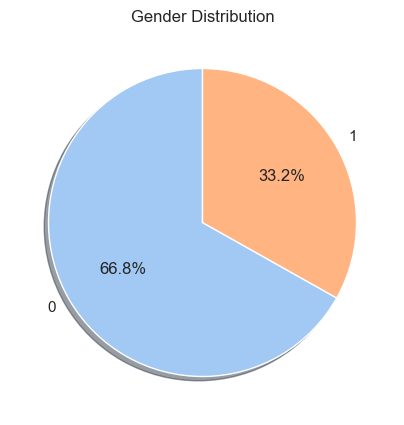

In [312]:
plt.figure(figsize=(5, 5))
df['gender'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, shadow=True)
plt.title("Gender Distribution")
plt.ylabel("")  # Hide y-label
plt.show()


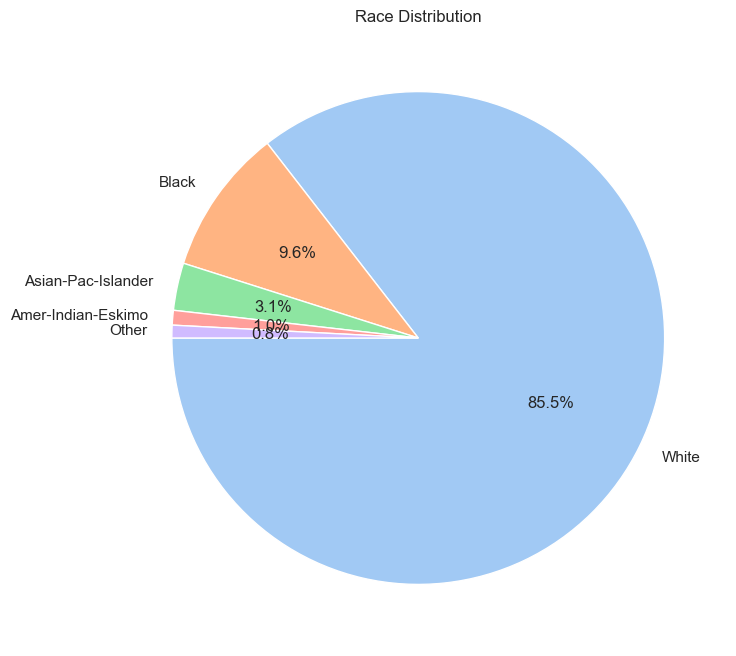

In [316]:
plt.figure(figsize=(8, 8))
df['race'].value_counts().plot.pie(autopct='%1.1f%%', startangle=180)
plt.title("Race Distribution")
plt.ylabel("")
plt.show()


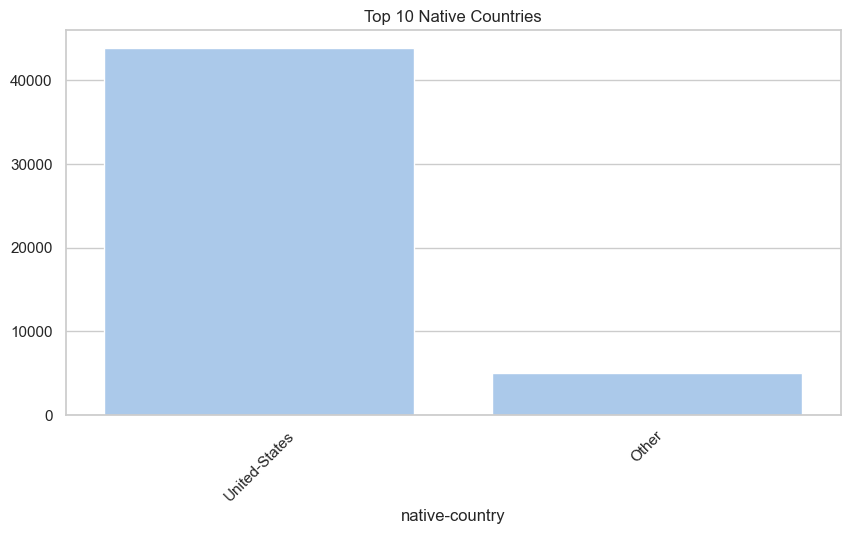

In [317]:
plt.figure(figsize=(10, 5))
top_countries = df['native-country'].value_counts().head(10)
sns.barplot(x=top_countries.index, y=top_countries.values)
plt.title("Top 10 Native Countries")
plt.xticks(rotation=45)
plt.show()


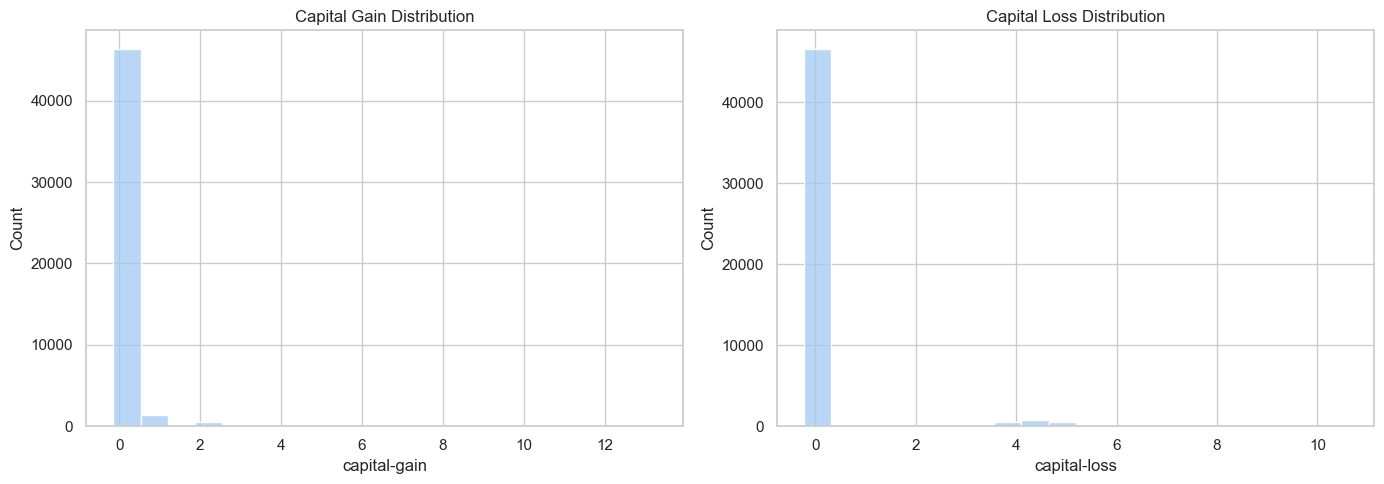

In [318]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['capital-gain'], bins=20, ax=axes[0])
axes[0].set_title("Capital Gain Distribution")

sns.histplot(df['capital-loss'], bins=20, ax=axes[1])
axes[1].set_title("Capital Loss Distribution")

plt.tight_layout()
plt.show()


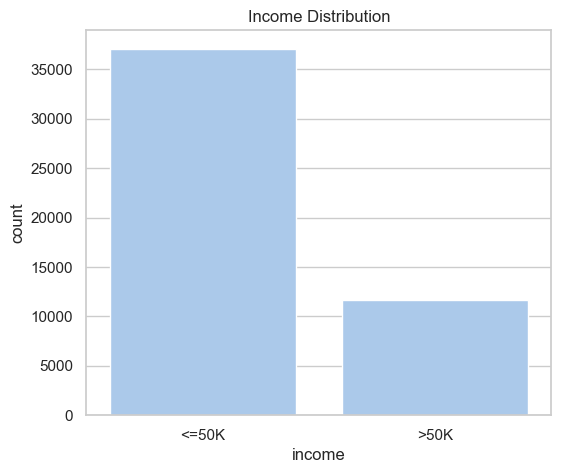

In [319]:
plt.figure(figsize=(6, 5))
sns.countplot(x='income', data=df)
plt.title("Income Distribution")
plt.show()


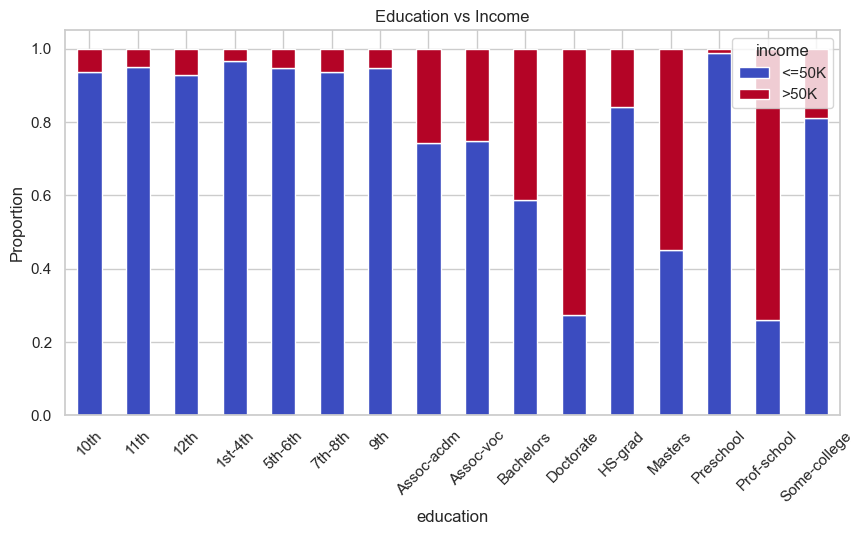

In [320]:
edu_income = pd.crosstab(df['education'], df['income'], normalize='index')
edu_income.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='coolwarm')
plt.title("Education vs Income")
plt.ylabel("Proportion")
plt.xticks(rotation=45)
plt.show()


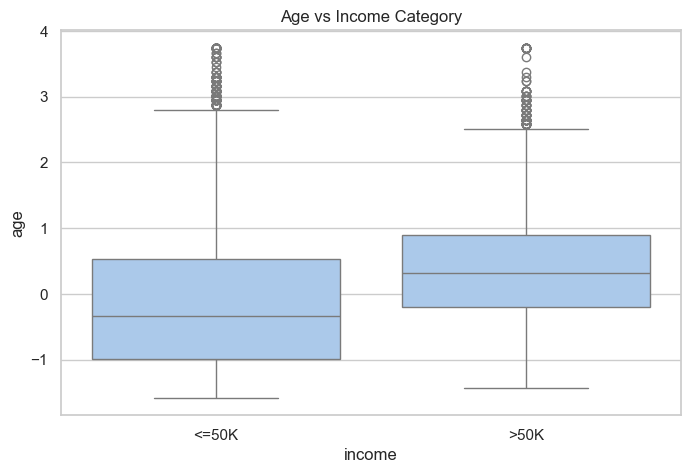

In [321]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='income', y='age', data=df)
plt.title("Age vs Income Category")
plt.show()


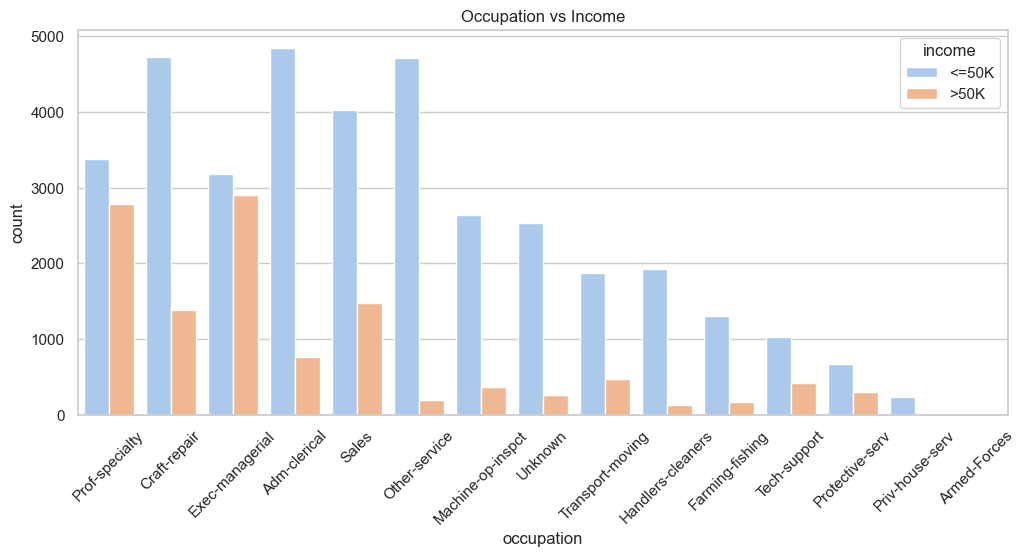

In [322]:
plt.figure(figsize=(12, 5))
sns.countplot(x='occupation', hue='income', data=df,
              order=df['occupation'].value_counts().index)
plt.title("Occupation vs Income")
plt.xticks(rotation=45)
plt.show()


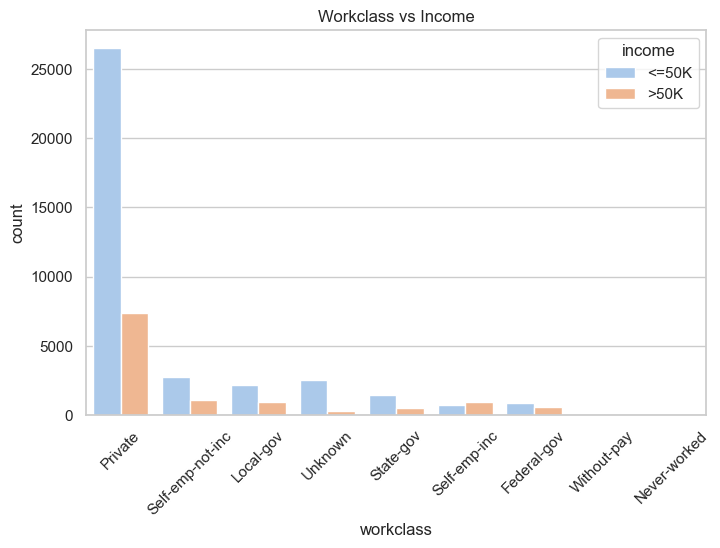

In [323]:
plt.figure(figsize=(8, 5))
sns.countplot(x='workclass', hue='income', data=df,
              order=df['workclass'].value_counts().index)
plt.title("Workclass vs Income")
plt.xticks(rotation=45)
plt.show()


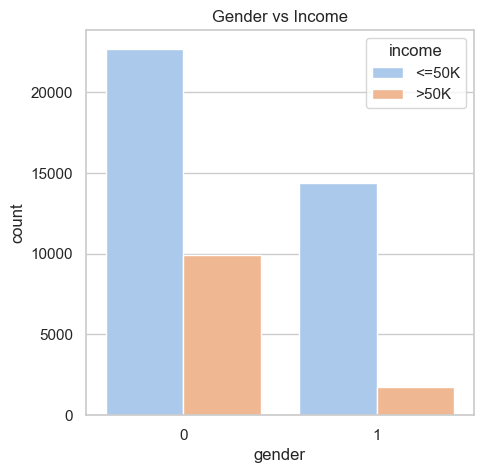

In [326]:
plt.figure(figsize=(5, 5))
sns.countplot(x='gender', hue='income', data=df)
plt.title("Gender vs Income")
plt.show()


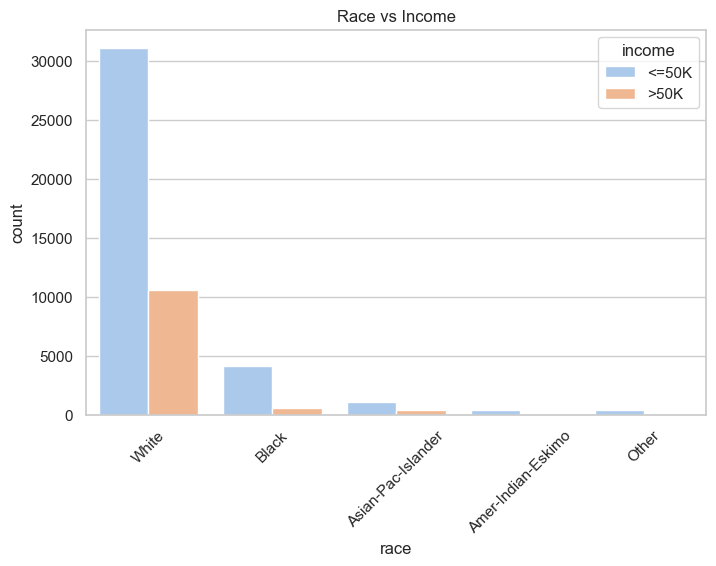

In [327]:
plt.figure(figsize=(8, 5))
sns.countplot(x='race', hue='income', data=df,
              order=df['race'].value_counts().index)
plt.title("Race vs Income")
plt.xticks(rotation=45)
plt.show()


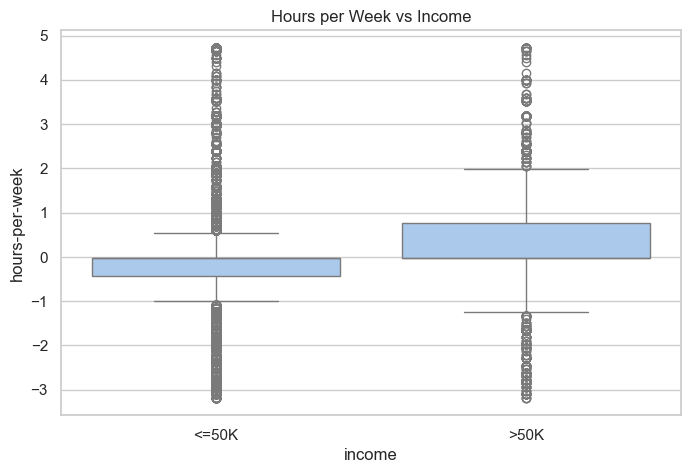

In [328]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='income', y='hours-per-week', data=df)
plt.title("Hours per Week vs Income")
plt.show()


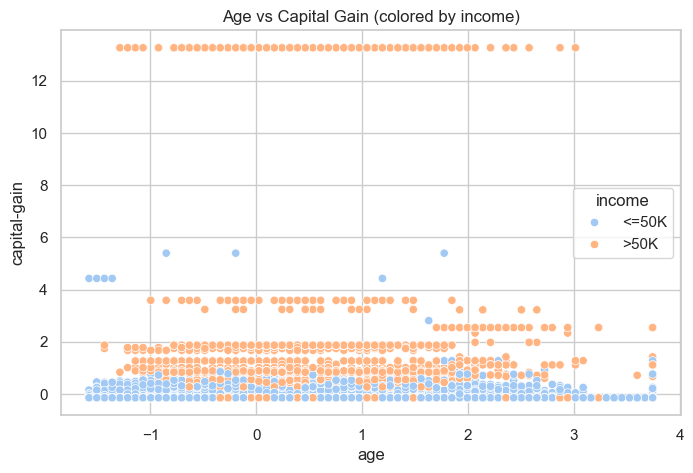

In [329]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='age', y='capital-gain', hue='income', data=df)
plt.title("Age vs Capital Gain (colored by income)")
plt.show()


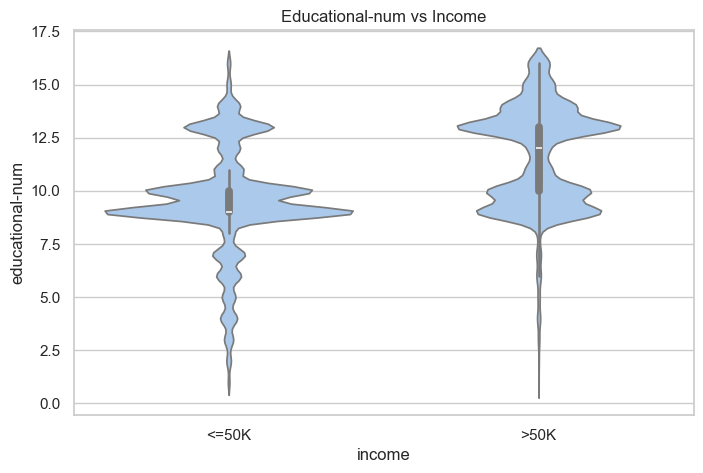

In [330]:
plt.figure(figsize=(8, 5))
sns.violinplot(x='income', y='educational-num', data=df)
plt.title("Educational-num vs Income")
plt.show()


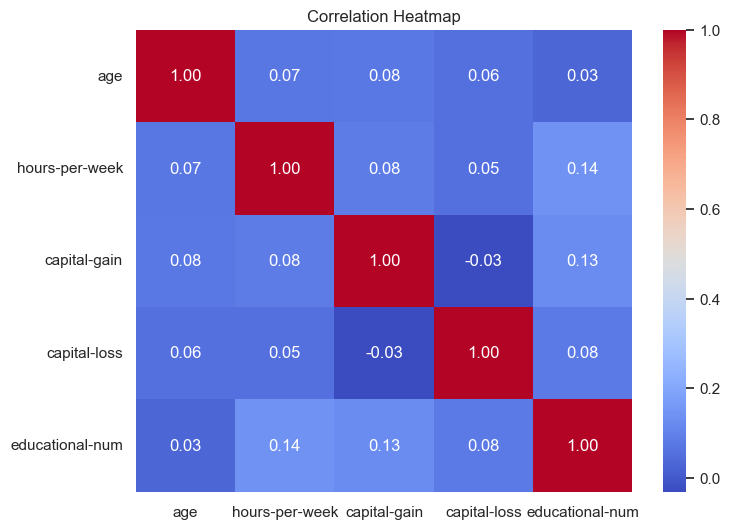

In [331]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[['age', 'hours-per-week', 'capital-gain', 'capital-loss', 'educational-num']].corr(),
            annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


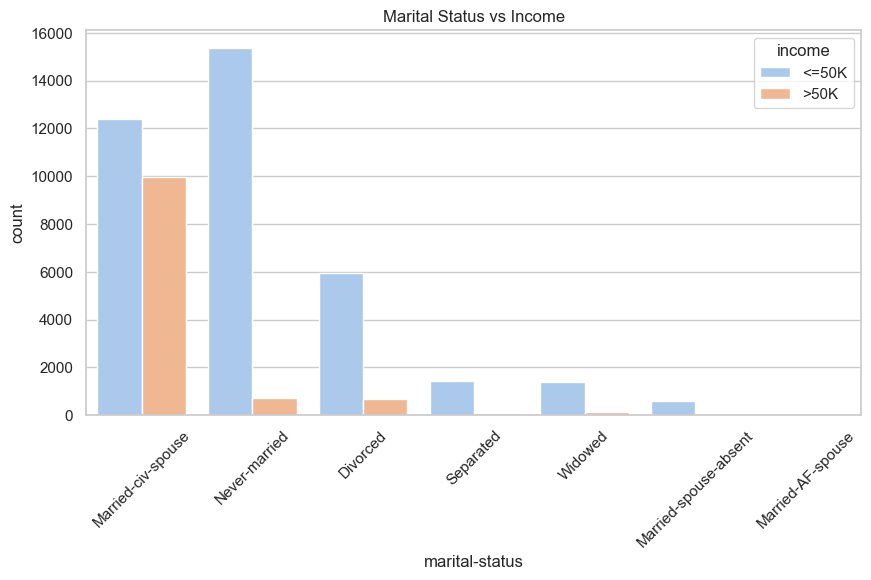

In [332]:
plt.figure(figsize=(10, 5))
sns.countplot(x='marital-status', hue='income', data=df,
              order=df['marital-status'].value_counts().index)
plt.title("Marital Status vs Income")
plt.xticks(rotation=45)
plt.show()


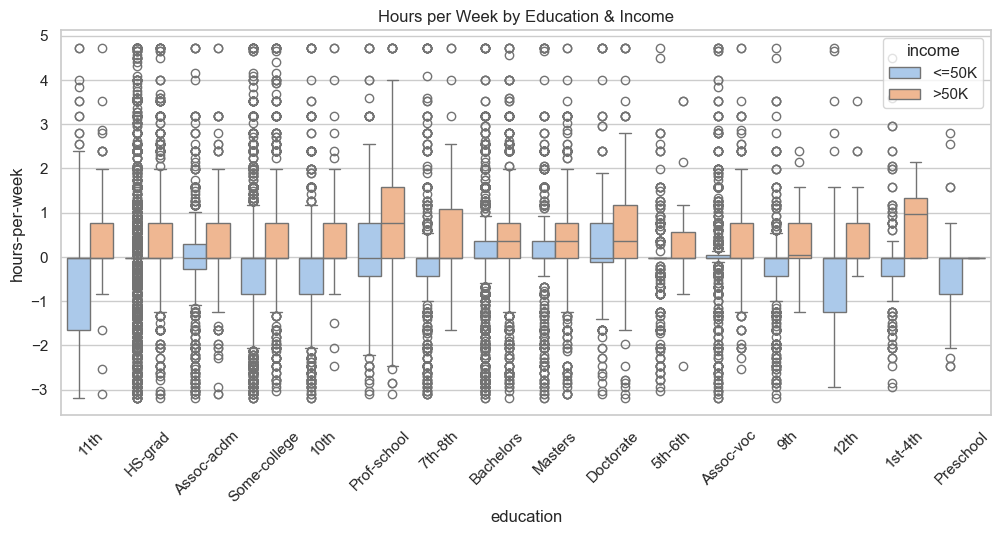

In [333]:
plt.figure(figsize=(12, 5))
sns.boxplot(x='education', y='hours-per-week', hue='income', data=df)
plt.title("Hours per Week by Education & Income")
plt.xticks(rotation=45)
plt.show()


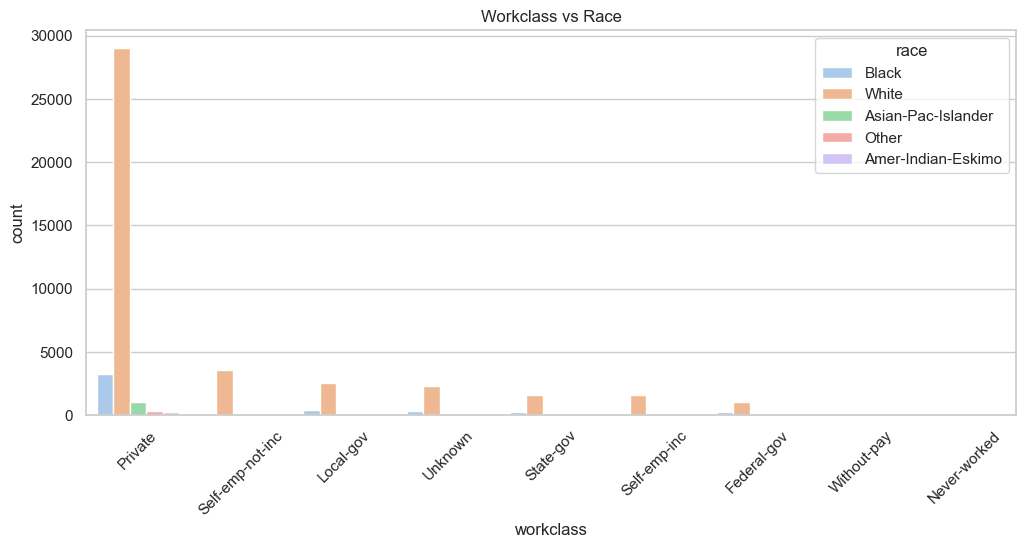

In [334]:
plt.figure(figsize=(12, 5))
sns.countplot(x='workclass', hue='race', data=df,
              order=df['workclass'].value_counts().index)
plt.title("Workclass vs Race")
plt.xticks(rotation=45)
plt.show()


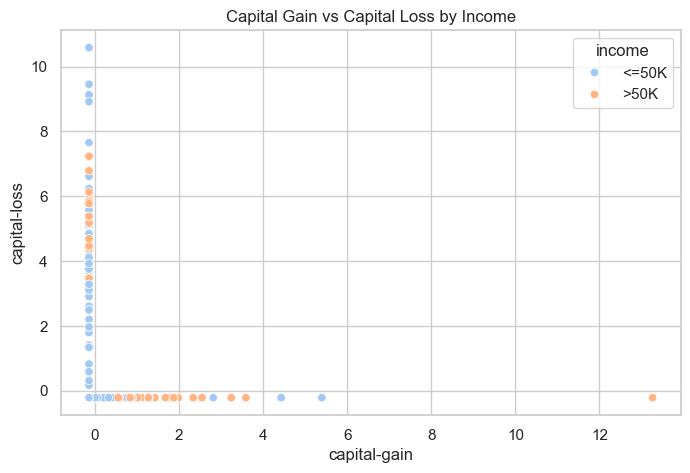

In [335]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='capital-gain', y='capital-loss', hue='income', data=df)
plt.title("Capital Gain vs Capital Loss by Income")
plt.show()
